# Western Australia Road Crash and School Speed Zone Analysis

## 1. Introduction

Road safety is an important concern in Western Australia, particularly around schools where pedestrians, cyclists, motorists and other road users interact.

This project investigates historical road crash records and designated school speed zones in Western Australia to identify crash patterns, examine severity, and explore geographical and temporal relationships.

### Research Question

How can historical road crash patterns and school speed zone information help identify higher risk road locations and inform targeted road safety policies in Western Australia?

### Project Objectives

1. Examine and validate road crash and school speed zone datasets.
2. Identify missing values, duplicate records and inconsistent data.
3. Investigate whether crash locations can be matched to designated school speed zone segments.
4. Analyse crash severity, road user involvement and temporal patterns.
5. Apply feature engineering, sorting and visualisation techniques.
6. Use PCA and NMF to explore underlying patterns in crash characteristics.
7. Present evidence based findings and potential road safety policy considerations.

### Limitations

The analysis is observational. Geographic matching does not establish that a school speed zone was active at the time of a crash. Historical speed zone changes, school calendars and actual vehicle speeds may not be available. The project therefore does not claim causal relationships between speed limits and crash outcomes.

## 2. Data Sources and Notebook Setup

This project uses two publicly available datasets published by **Main Roads Western Australia** through the WA Government Open Data Catalogue (data.wa.gov.au).

### Dataset 1: Crash Information (Last 5 Years)

- **Publisher:** Main Roads Western Australia
- **Source:** https://catalogue.data.wa.gov.au/dataset/mrwa-crash-information-last-5-years-
- **Period analysed:** 2021–2025
- **Download Date:** October 2026

This dataset contains reported road crashes in Western Australia, including crash dates, times, locations, severity and road user involvement.

### Dataset 2: Legal Speed Zones

- **Publisher:** Main Roads Western Australia
- **Source:** https://catalogue.data.wa.gov.au/dataset/mrwa-legal-speed-zones
- **Data type:** Current snapshot of school speed zone segments
- **Download Date:** October 2026

This dataset identifies road segments with designated speed zones, including school zones.

### Important Limitation: Historical Speed Zone Changes

The crash dataset contains historical records, while the speed zone dataset represents road zone information available at the time it was downloaded.

This creates a limitation when matching the two datasets. For example, a school speed zone introduced in 2024 could appear in the speed zone dataset even when analysing a crash from 2021.

Therefore, matching a crash to a road segment does not prove that the same speed restriction existed or was operating when the crash occurred.

The analysis also does not confirm individual school operating days, school holidays or whether a temporary speed restriction was active at the exact crash time.

For these reasons, the matching results are used to explore possible crash patterns and locations, rather than to establish the effect of school speed limits on crashes.

### Notebook Setup

Both CSV files are stored in Google Drive and loaded into Google Colab. The following code connects to Google Drive and checks that the required files are available before starting the analysis.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

# Defining project directory
PROJECT_DIR = Path("/content/drive/MyDrive/WA_Road_Safety_Project")

# Checking that both datasets exist
crash_file = PROJECT_DIR / "data/raw/Crash_Information.csv"
speed_file = PROJECT_DIR / "data/raw/Legal_Speed_Zones.csv"

print("Crash dataset found:", crash_file.exists())
print("Speed zone dataset found:", speed_file.exists())


Crash dataset found: True
Speed zone dataset found: True


## 3. Initial Dataset Exploration
The first stage inspects the size, columns, data types, completeness and sample records of both datasets. This helps identify data quality issues before matching records or making comparisons.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Original CSV files
crash_df = pd.read_csv(crash_file, low_memory=False)
speed_df = pd.read_csv(speed_file, low_memory=False)

print("Crash dataset:", crash_df.shape)
print("Speed zone dataset:", speed_df.shape)


Crash dataset: (132862, 25)
Speed zone dataset: (6510, 19)


In [ ]:
# The first five rows of each dataset
print("CRASH DATASET - FIRST 5 RECORDS")
display(crash_df.head())

print("SPEED ZONE DATASET - FIRST 5 RECORDS")
display(speed_df.head())

CRASH DATASET - FIRST 5 RECORDS


,X,Y,ACC_ID,ROAD_NO,ROAD_NAME,COMMON_ROAD_NAME,CWAY,SLK,INTERSECTION_NO,INTERSECTION_DESC,...,SEVERITY,EVENT_NATURE,EVENT_TYPE,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED,OBJECTID
0,115.796499,-32.083481,11162988,H002,Melville Mandurah Hwy,Stock Rd,R,3.96,NaN,NaN,...,Hospital,Hit Object,NaN,0,0,0,0,1,0,1
1,116.032510,-31.521590,11162993,H006,Great Northern Hwy,Great Northern Hwy,S,44.27,278418.0,Great Northern Hwy & Access Rd (Sugar Gum Dr),...,Medical,Right Angle,NaN,0,0,0,0,2,0,2
2,115.844374,-31.954050,11163001,1240096,Kings Park Rd,Kings Park Rd,L,1.10,50608.0,Kings Park Rd & Malcolm St & Fraser Av,...,Medical,Right Angle,NaN,0,0,0,0,2,0,3
3,115.874578,-31.982294,11163009,1260297,Broome St,Broome St,S,0.04,162704.0,Broome St & R.O.W. 44,...,Medical,Right Angle,NaN,0,0,0,0,2,0,4
4,117.868063,-35.003973,11163017,3021015,North Rd,North Rd,R,0.18,NaN,NaN,...,Medical,Rear End,NaN,0,0,0,0,2,0,5


SPEED ZONE DATASET - FIRST 5 RECORDS


,ROAD,ROAD_NAME,COMMON_USAGE_NAME,START_SLK,END_SLK,CWY,START_TRUE_DIST,END_TRUE_DIST,NETWORK_TYPE,RA_NO,RA_NAME,LG_NO,LG_NAME,SPEED_ZONE_SIGN_TYPE,SPEED_ZONE_SIGN_VALUE,ROUTE_NE_ID,OBJECTID,GlobalID,GEOLOCSTLength
0,1190145,View Tce,View Tce,0.88,0.91,Single,0.88,0.91,Local Road,7,Metropolitan,119,Melville (C),School Zone Speed Limit: 40km/h - Operating ti...,MR-RS-7B,244063,2704792,{D84911BC-5DA3-41A7-8465-11DC7D7D6AB7},0.000313
1,1190145,View Tce,View Tce,0.91,0.92,Single,0.91,0.92,Local Road,7,Metropolitan,119,Melville (C),School Zone Speed Limit: 40km/h - Operating ti...,MR-RS-7B,244063,2704793,{8E4CE99E-A2C9-4F6D-B840-1901532630BA},0.000104
2,1190145,View Tce,View Tce,1.05,1.06,Single,1.05,1.06,Local Road,7,Metropolitan,119,Melville (C),School Zone Speed Limit: 40km/h - Operating ti...,MR-RS-7B,244063,2704794,{FE0417A8-96F0-4390-B166-9CE0C5DEB6B5},0.000112
3,1130224,Hendra St,Hendra St,0.20,0.23,Single,0.20,0.23,Local Road,7,Metropolitan,113,Belmont (C),School Zone Speed Limit: 40km/h - Operating ti...,MR-RS-7B,219500,2704795,{E23DD0FB-63F3-4AAF-9FED-6370E2D6A18F},0.000289
4,1130224,Hendra St,Hendra St,0.23,0.25,Single,0.23,0.25,Local Road,7,Metropolitan,113,Belmont (C),School Zone Speed Limit: 40km/h - Operating ti...,MR-RS-7B,219500,2704796,{E934F0AB-7E0F-4035-BDC2-FE6457CD91E1},0.000192


In [ ]:
# Column information table
def column_summary(df):
    return pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Non-Null Count": df.notna().sum().values,
        "Missing Count": df.isna().sum().values,
        "Unique Values": df.nunique(dropna=True).values
    })

print("CRASH DATASET - COLUMN SUMMARY")
display(column_summary(crash_df))


CRASH DATASET - COLUMN SUMMARY


,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,X,float64,132862,0,60154
1,Y,float64,132862,0,61786
2,ACC_ID,int64,132862,0,132862
3,ROAD_NO,object,132862,0,12474
4,ROAD_NAME,object,132862,0,10654
5,COMMON_ROAD_NAME,object,132862,0,10709
6,CWAY,object,132862,0,3
7,SLK,float64,132862,0,8004
8,INTERSECTION_NO,float64,71521,61341,13692
9,INTERSECTION_DESC,object,71521,61341,13453


In [ ]:
print("SPEED ZONE DATASET - COLUMN SUMMARY")
display(column_summary(speed_df))

SPEED ZONE DATASET - COLUMN SUMMARY


,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,ROAD,object,6510,0,2808
1,ROAD_NAME,object,6510,0,2588
2,COMMON_USAGE_NAME,object,6510,0,2590
3,START_SLK,float64,6510,0,1456
4,END_SLK,float64,6510,0,1504
5,CWY,object,6510,0,3
6,START_TRUE_DIST,float64,6510,0,1451
7,END_TRUE_DIST,float64,6510,0,1506
8,NETWORK_TYPE,object,6510,0,3
9,RA_NO,int64,6510,0,8


### 3.1 Missing Data Assessment
Missing values are counted by column and visualised for the crash dataset. Missing data is investigated rather than automatically deleted, since some fields may be unavailable for legitimate reasons.

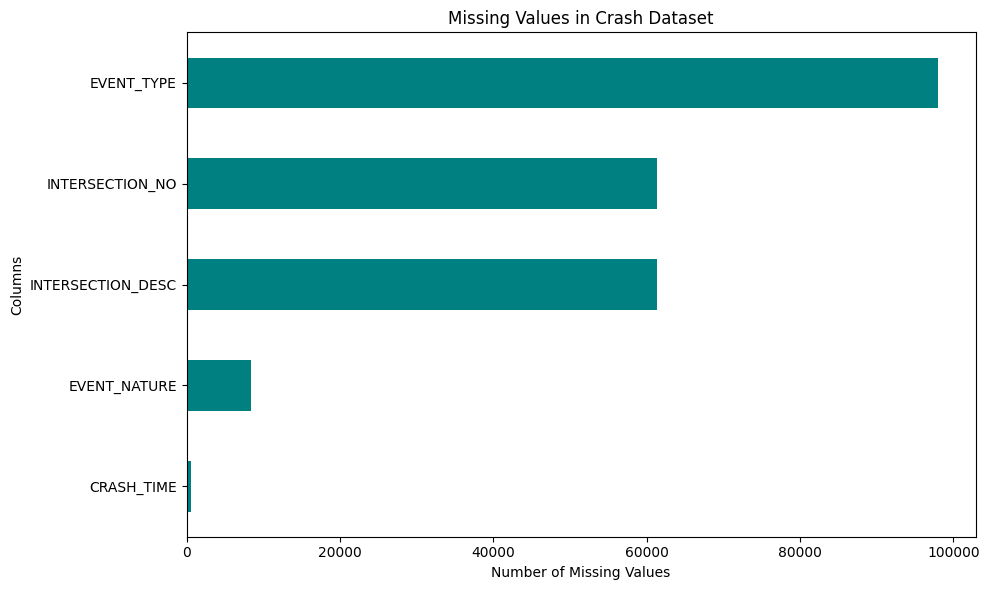

In [ ]:
# Crash Dataset - Missing Values Bar Graph

missing_values = crash_df.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values.sort_values().plot(kind='barh', figsize=(10, 6), color='teal')
plt.title('Missing Values in Crash Dataset')
plt.xlabel('Number of Missing Values')
plt.ylabel('Columns')
plt.tight_layout()
plt.show()


**Findings — Missing Values in Crash Dataset**

The missing values bar graph identifies five columns containing incomplete records.

`EVENT_TYPE` has the highest number of missing values (73.76%), followed by `INTERSECTION_NO` and `INTERSECTION_DESC` (46.17% each).

The missing intersection information may be associated with crashes occurring outside intersections. However, further investigation is required to confirm this.

`EVENT_NATURE` contains 6.28% missing values, while `CRASH_TIME` has only 0.39%.

These findings indicate that missing values should be investigated individually rather than removing all incomplete records. Appropriate cleaning methods will be selected based on the purpose and characteristics of each column.


### 3.2 Investigating Missing Crash Attributes
The following checks examine whether missing EVENT_TYPE, intersection details, EVENT_NATURE and CRASH_TIME are associated with particular accident types. Percentages are calculated within accident types to make comparisons more meaningful.

In [ ]:
# Investigating EVENT_TYPE
print("EVENT_TYPE - VALUE DISTRIBUTION")
print(crash_df['EVENT_TYPE'].value_counts(dropna=False))

EVENT_TYPE - VALUE DISTRIBUTION
EVENT_TYPE
NaN                            98004
Involving Overtaking           12990
Involving Parking               9921
Entering / Leaving Driveway     7932
Involving Animal                2252
Involving Pedestrian            1763
Name: count, dtype: int64


In [ ]:
# Investigating missing EVENT_TYPE by accident type
print("ACCIDENT TYPES WHERE EVENT_TYPE IS MISSING")
missing_event = crash_df[crash_df['EVENT_TYPE'].isnull()]
print(missing_event['ACCIDENT_TYPE'].value_counts())

ACCIDENT TYPES WHERE EVENT_TYPE IS MISSING
ACCIDENT_TYPE
Intersection                   66091
Midblock                       31912
Roads Open To Public Access        1
Name: count, dtype: int64


In [ ]:
# Percentage of missing EVENT_TYPE within each accident type
print("MISSING EVENT_TYPE PERCENTAGE BY ACCIDENT TYPE")
missing_percentage = (crash_df.groupby('ACCIDENT_TYPE')['EVENT_TYPE'].apply(lambda x: x.isnull().mean() * 100))
print(missing_percentage.round(2))


MISSING EVENT_TYPE PERCENTAGE BY ACCIDENT TYPE
ACCIDENT_TYPE
Intersection                    92.41
Midblock                        52.02
Roads Open To Public Access    100.00
Name: EVENT_TYPE, dtype: float64


In [ ]:
# Excluding a single record category to avoid misleading percentages
# The original record remains in the dataset
missing_percentage = missing_percentage.drop('Roads Open To Public Access')
print("MISSING EVENT_TYPE PERCENTAGE BY ACCIDENT TYPE")
print(missing_percentage.round(2))

MISSING EVENT_TYPE PERCENTAGE BY ACCIDENT TYPE
ACCIDENT_TYPE
Intersection    92.41
Midblock        52.02
Name: EVENT_TYPE, dtype: float64


In [ ]:
# Investigating missing intersection information
print("MISSING INTERSECTION INFORMATION BY ACCIDENT TYPE")
missing_intersection = crash_df[crash_df['INTERSECTION_NO'].isnull()]
print(missing_intersection['ACCIDENT_TYPE'].value_counts())

MISSING INTERSECTION INFORMATION BY ACCIDENT TYPE
ACCIDENT_TYPE
Midblock                       61333
Intersection                       7
Roads Open To Public Access        1
Name: count, dtype: int64


In [ ]:
# Investigating intersection crashes with missing intersection numbers
print("INTERSECTION CRASHES WITH MISSING INTERSECTION NUMBERS")
display(missing_intersection[missing_intersection['ACCIDENT_TYPE'] == 'Intersection'][['ACC_ID', 'ROAD_NAME', 'INTERSECTION_NO','INTERSECTION_DESC', 'SEVERITY']])


INTERSECTION CRASHES WITH MISSING INTERSECTION NUMBERS


,ACC_ID,ROAD_NAME,INTERSECTION_NO,INTERSECTION_DESC,SEVERITY
52486,10659021,South Western Hwy,NaN,NaN,Fatal
55775,10685607,Midgegooroo Av,NaN,NaN,PDO Major
76147,10873930,Great Eastern Hwy,NaN,NaN,PDO Minor
77957,10887912,Farrington Rd,NaN,NaN,PDO Major
91708,11018129,Stirling Hwy,NaN,NaN,Fatal
100012,11078796,Marvel Loch - Forrestania Rd,NaN,NaN,Medical
126576,11433671,Murray Rd,NaN,NaN,PDO Major


In [ ]:
# Checking location information for the seven intersection crashes
print("LOCATION INFORMATION FOR INTERSECTION CRASHES")
display(missing_intersection[missing_intersection['ACCIDENT_TYPE'] == 'Intersection'][['ACC_ID', 'ROAD_NAME', 'ROAD_NO','SLK', 'LATITUDE', 'LONGITUDE']])


LOCATION INFORMATION FOR INTERSECTION CRASHES


,ACC_ID,ROAD_NAME,ROAD_NO,SLK,LATITUDE,LONGITUDE
52486,10659021,South Western Hwy,H009,235.34,-33.900185,116.103086
55775,10685607,Midgegooroo Av,1032307,0.27,-32.126198,115.853999
76147,10873930,Great Eastern Hwy,H005,317.78,-31.369782,118.860325
77957,10887912,Farrington Rd,1190997,1.89,-32.079202,115.845886
91708,11018129,Stirling Hwy,H014,14.05,-32.026938,115.752511
100012,11078796,Marvel Loch - Forrestania Rd,4100098,30.73,-32.476086,119.761537
126576,11433671,Murray Rd,3180068,7.98,-34.290912,119.273374


In [ ]:
# Investigating missing EVENT_NATURE by accident type
print("MISSING EVENT_NATURE BY ACCIDENT TYPE")
missing_nature = crash_df[crash_df['EVENT_NATURE'].isnull()]
print(missing_nature['ACCIDENT_TYPE'].value_counts())


MISSING EVENT_NATURE BY ACCIDENT TYPE
ACCIDENT_TYPE
Midblock        6493
Intersection    1854
Name: count, dtype: int64


In [ ]:
# Percentage of missing EVENT_NATURE by accident type
print("MISSING EVENT_NATURE PERCENTAGE BY ACCIDENT TYPE")
nature_percentage = (crash_df.groupby('ACCIDENT_TYPE')['EVENT_NATURE'].apply(lambda x: x.isnull().mean() * 100))
print(nature_percentage.round(2))

MISSING EVENT_NATURE PERCENTAGE BY ACCIDENT TYPE
ACCIDENT_TYPE
Intersection                    2.59
Midblock                       10.58
Roads Open To Public Access     0.00
Name: EVENT_NATURE, dtype: float64


In [ ]:
# Investigating missing CRASH_TIME by accident type
print("MISSING CRASH_TIME BY ACCIDENT TYPE")
missing_time = crash_df[crash_df['CRASH_TIME'].isnull()]
print(missing_time['ACCIDENT_TYPE'].value_counts())

MISSING CRASH_TIME BY ACCIDENT TYPE
ACCIDENT_TYPE
Intersection    273
Midblock        246
Name: count, dtype: int64


In [ ]:
# Percentage of missing CRASH_TIME by accident type
print("MISSING CRASH_TIME PERCENTAGE BY ACCIDENT TYPE")
time_percentage = (crash_df.groupby('ACCIDENT_TYPE')['CRASH_TIME'].apply(lambda x: x.isnull().mean() * 100))
print(time_percentage.round(2))


MISSING CRASH_TIME PERCENTAGE BY ACCIDENT TYPE
ACCIDENT_TYPE
Intersection                   0.38
Midblock                       0.40
Roads Open To Public Access    0.00
Name: CRASH_TIME, dtype: float64


### 3.3 Duplicate Record Checks
Duplicate full rows and duplicate identifiers are checked separately. Identifiers help assess whether a record represents a distinct crash or speed zone entry.

In [ ]:
# Checking duplicate records in Crash Dataset
print("DUPLICATE CRASH RECORDS")
print("Duplicate rows:", crash_df.duplicated().sum())
print("Duplicate ACC_ID:", crash_df['ACC_ID'].duplicated().sum())

DUPLICATE CRASH RECORDS
Duplicate rows: 0
Duplicate ACC_ID: 0


In [ ]:
# Checking duplicate records in Speed Zone Dataset
print("DUPLICATE SPEED ZONE RECORDS")
print("Duplicate rows:", speed_df.duplicated().sum())
print("Duplicate OBJECTID:", speed_df['OBJECTID'].duplicated().sum())

DUPLICATE SPEED ZONE RECORDS
Duplicate rows: 0
Duplicate OBJECTID: 0


### 3.4 School Speed Zone Characteristics
The speed zone dataset is explored to understand recorded operating descriptions and the distribution of zone schedules. These descriptions alone do not confirm whether a restriction applied at the time of a historical crash.

In [ ]:
# Investigating school speed zone operating descriptions
print("SCHOOL SPEED ZONE OPERATING DESCRIPTIONS")
print(speed_df['SPEED_ZONE_SIGN_TYPE'].value_counts())

SCHOOL SPEED ZONE OPERATING DESCRIPTIONS
SPEED_ZONE_SIGN_TYPE
School Zone Speed Limit: 40km/h - Operating times 7:30 am to 9:00 am and 2:30 pm to 4:00 pm on School Days    5881
School Zone Speed Limit: 40km/h - Children Crossing (AM 7:30-9:00 PM 14:30-16:00)                              351
School Zone Speed Limit: 40km/h - Operating times 7:30 am to 9:00 am and 2:00 pm to 3:30 pm on School Days     167
School Zone Speed Limit: 40km/h - School Zone (AM : 7:00-8:30 PM : 14:00-15:30)                                108
School Zone Speed Limit: 40km/h - Operating times 7:30 am to 9:00 am and 2:00 pm to 4:00 pm on School Days       3
Name: count, dtype: int64


## 4. Road Identifiers and Segment Quality
Before merging, the analysis compares road identifiers across datasets, examines carriageway coding and validates school zone segment start and end positions. Segment lengths are investigated for unusual values; potential outliers are flagged for review rather than removed automatically.

In [ ]:
# Investigating unique road identifiers
print("UNIQUE ROAD IDENTIFIERS")
print("Crash Dataset:",crash_df['ROAD_NO'].nunique())
print("Speed Zone Dataset:",speed_df['ROAD'].nunique())

UNIQUE ROAD IDENTIFIERS
Crash Dataset: 12474
Speed Zone Dataset: 2808


In [ ]:
# Investigating shared road identifiers
print("SHARED ROAD IDENTIFIERS")
shared_roads = speed_df[speed_df['ROAD'].isin(crash_df['ROAD_NO'])]
print("Shared unique roads:", shared_roads['ROAD'].nunique())
print("Matching speed zone records:", len(shared_roads))

SHARED ROAD IDENTIFIERS
Shared unique roads: 1547
Matching speed zone records: 4298


In [ ]:
# Counting crashes on shared road identifiers
print("CRASHES ON ROADS WITH SCHOOL SPEED ZONES")
shared_crashes = crash_df[crash_df['ROAD_NO'].isin(shared_roads['ROAD'])]
print("Matching crash records:", len(shared_crashes))
print("Unique roads:", shared_crashes['ROAD_NO'].nunique())


CRASHES ON ROADS WITH SCHOOL SPEED ZONES
Matching crash records: 48492
Unique roads: 1547


In [ ]:
# Examining crash road location information
print("CRASH DATASET - ROAD LOCATION INFORMATION")
display(shared_crashes[['ROAD_NO', 'ROAD_NAME', 'CWAY', 'SLK']].head(10))

CRASH DATASET - ROAD LOCATION INFORMATION


,ROAD_NO,ROAD_NAME,CWAY,SLK
4,3021015,North Rd,R,0.18
6,1250052,Central Av,S,1.52
11,2040018,Parade Rd,L,0.00
12,1030004,Winterfold Rd,S,0.11
16,H027,Rivervale Wattle Grove Link,R,9.36
20,H027,Rivervale Wattle Grove Link,L,8.00
24,1260010,Murray St,S,0.16
27,1120005,Beechboro Rd North,S,0.39
31,1140005,Treasure Rd,S,1.08
35,1140006,Wharf St,S,2.59


In [ ]:
# Examining school speed zone road location information
print("SPEED ZONE DATASET - ROAD LOCATION INFORMATION")
display(shared_roads[['ROAD', 'ROAD_NAME', 'CWY', 'START_SLK', 'END_SLK']].head(10))

SPEED ZONE DATASET - ROAD LOCATION INFORMATION


,ROAD,ROAD_NAME,CWY,START_SLK,END_SLK
0,1190145,View Tce,Single,0.88,0.91
1,1190145,View Tce,Single,0.91,0.92
2,1190145,View Tce,Single,1.05,1.06
3,1130224,Hendra St,Single,0.20,0.23
4,1130224,Hendra St,Single,0.23,0.25
5,1130224,Hendra St,Single,0.25,0.28
6,1260337,George St,Single,0.00,0.09
7,1220026,Melvista Av,Single,0.29,0.45
8,1190084,Gunbower Rd,Single,0.61,0.65
9,1190084,Gunbower Rd,Single,0.65,0.94


In [ ]:
# Investigating carriageway categories
print("CRASH DATASET - CARRIAGEWAY CODES")
print(crash_df['CWAY'].value_counts(dropna=False))
print("\nSPEED ZONE DATASET - CARRIAGEWAY CODES")
print(speed_df['CWY'].value_counts(dropna=False))

CRASH DATASET - CARRIAGEWAY CODES
CWAY
S    71801
L    47100
R    13961
Name: count, dtype: int64

SPEED ZONE DATASET - CARRIAGEWAY CODES
CWY
Single    5610
Left       511
Right      389
Name: count, dtype: int64


In [ ]:
# Checking school speed zone segment boundaries
print("SPEED ZONE SEGMENT VALIDATION")
print("Segments with START_SLK greater than END_SLK:",(speed_df['START_SLK'] > speed_df['END_SLK']).sum())
print("Segments with START_SLK equal to END_SLK:",(speed_df['START_SLK'] == speed_df['END_SLK']).sum())

SPEED ZONE SEGMENT VALIDATION
Segments with START_SLK greater than END_SLK: 0
Segments with START_SLK equal to END_SLK: 0


In [ ]:
# Investigating school speed zone segment lengths
print("SCHOOL SPEED ZONE SEGMENT LENGTHS")
segment_length = speed_df['END_SLK'] - speed_df['START_SLK']
print(segment_length.describe())

SCHOOL SPEED ZONE SEGMENT LENGTHS
count    6510.000000
mean        0.122873
std         0.124410
min         0.001000
25%         0.030000
50%         0.078000
75%         0.180000
max         1.100000
dtype: float64


In [ ]:
# Counting potential outliers in segment lengths
Q1 = segment_length.quantile(0.25)
Q3 = segment_length.quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
outliers = segment_length[segment_length > upper_limit]
print("Upper outlier limit (km):", round(upper_limit, 3))
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:", round(len(outliers) / len(segment_length) * 100, 2))

Upper outlier limit (km): 0.405
Number of potential outliers: 218
Percentage of potential outliers: 3.35


In [ ]:
# Investigating the 10 longest school speed zone segments
print("TOP 10 LONGEST SCHOOL SPEED ZONE SEGMENTS")
longest_segments = speed_df.copy()
longest_segments['SEGMENT_LENGTH'] = segment_length
display(longest_segments[['ROAD', 'ROAD_NAME', 'CWY','START_SLK', 'END_SLK', 'SEGMENT_LENGTH']].sort_values('SEGMENT_LENGTH', ascending=False).head(10))

TOP 10 LONGEST SCHOOL SPEED ZONE SEGMENTS


,ROAD,ROAD_NAME,CWY,START_SLK,END_SLK,SEGMENT_LENGTH
4803,2030408,Gleneagles Dr,Single,0.000,1.100,1.100
2156,5050004,Augustus St,Single,0.000,1.040,1.040
4331,1311551,Timberlane Dr,Single,0.000,0.910,0.910
5308,2060331,Dalyellup Bvd,Single,0.590,1.470,0.880
5536,1140154,Collins Rd,Single,0.360,1.210,0.850
1005,1010471,Skeet Rd,Single,1.333,2.164,0.831
4212,1011329,Reilly Rd,Single,0.000,0.820,0.820
6042,1251779,Silica Rd,Single,0.000,0.810,0.810
6049,2120397,Gordon Rd,Single,0.336,1.140,0.804
4678,1070611,Georgetown Dr,Single,0.169,0.970,0.801


In [ ]:
# Comparing segment lengths by carriageway type
print("SEGMENT LENGTHS BY CARRIAGEWAY TYPE")
print(longest_segments.groupby('CWY')['SEGMENT_LENGTH'].describe().round(3))

SEGMENT LENGTHS BY CARRIAGEWAY TYPE
         count   mean    std    min    25%    50%   75%    max
CWY                                                           
Left     511.0  0.108  0.121  0.001  0.024  0.060  0.14  0.740
Right    389.0  0.136  0.135  0.002  0.040  0.085  0.21  0.743
Single  5610.0  0.123  0.124  0.001  0.030  0.080  0.18  1.100



**Findings — School Speed Zone Segment Lengths by Carriageway**

The analysis found differences in recorded school speed zone segment lengths across carriageway categories.

Right carriageways had the highest average segment length (136 metres), followed by single carriageways (123 metres) and left carriageways (108 metres).

However, the longest individual segments were recorded on single carriageways, including Gleneagles Drive (1,100 metres) and Augustus Street (1,040 metres).

All three carriageway categories showed evidence of positively skewed distributions. These findings suggest that segment lengths vary across carriageway classifications, although further investigation is required to understand the reasons for these differences.


### 4.1 Repeated and Overlapping Segments
Repeated road/carriageway/SLK boundaries and potential segment overlaps are checked. These checks matter because one crash can otherwise match multiple zone records and inflate counts after merging.

In [ ]:
# Checking repeated school speed zone segment boundaries
print("REPEATED SCHOOL SPEED ZONE SEGMENTS")
print("Repeated road, carriageway and SLK boundaries:", speed_df.duplicated(subset=['ROAD', 'CWY', 'START_SLK', 'END_SLK']).sum())

REPEATED SCHOOL SPEED ZONE SEGMENTS
Repeated road, carriageway and SLK boundaries: 0


In [ ]:
# Sorting school speed zone segments by road and location
print("SCHOOL SPEED ZONE SEGMENTS - SORTED")
sorted_segments = speed_df.sort_values(by=['ROAD', 'CWY', 'START_SLK'])
display(sorted_segments[['ROAD', 'ROAD_NAME', 'CWY', 'START_SLK', 'END_SLK']].head(20))

SCHOOL SPEED ZONE SEGMENTS - SORTED


,ROAD,ROAD_NAME,CWY,START_SLK,END_SLK
3118,0010002,Guy St,Left,1.450,1.520
3119,0010002,Guy St,Left,1.520,1.710
3120,0010002,Guy St,Left,1.710,1.770
3121,0010002,Guy St,Right,1.450,1.500
3122,0010002,Guy St,Right,1.500,1.710
3123,0010002,Guy St,Right,1.710,1.770
3117,0010002,Guy St,Single,1.410,1.450
3124,0010033,Anne St,Single,0.130,0.135
3110,0010033,Anne St,Single,0.135,0.140
3111,0010033,Anne St,Single,0.140,0.145


In [ ]:
# Checking overlapping school speed zone segments
# Find the furthest previous segment end on each road and carriageway
previous_max_end = sorted_segments.groupby(['ROAD', 'CWY'])['END_SLK'].cummax()

# Move the previous maximum down by one row within each group
previous_max_end = previous_max_end.groupby([sorted_segments['ROAD'], sorted_segments['CWY']]).shift(1)

# Identify overlapping segments
overlapping_segments = sorted_segments[sorted_segments['START_SLK'] < previous_max_end]
print("OVERLAPPING SCHOOL SPEED ZONE SEGMENTS")
print("Number of overlapping records:", len(overlapping_segments))

# Display records only if overlaps exist
if len(overlapping_segments) > 0:
    display(overlapping_segments[['ROAD', 'ROAD_NAME', 'CWY', 'START_SLK', 'END_SLK']].head(10))


OVERLAPPING SCHOOL SPEED ZONE SEGMENTS
Number of overlapping records: 0



**Findings — Overlapping School Speed Zone Segments**

The overlap validation identified no overlapping school speed zone segments within the same road and carriageway.

This indicates that no segment started before the furthest endpoint of a preceding segment within its road and carriageway group.

The result supports the consistency of the recorded segment boundaries.

However, segments sharing an endpoint were not classified as overlapping, and the analysis does not independently verify the geographic accuracy of the recorded boundaries.


## 5. Data Preparation and Geographic Matching
The crash and speed zone datasets use different carriageway labels. Crash codes are standardised before joining on road identifier and carriageway. A second filter checks whether each crash SLK falls between the recorded start and end SLK of a speed zone segment.

Important: This is a road segment match, not proof that a school speed limit was active on the crash date. A crash can initially match more than one segment, so unique crash identifiers are used when reporting crash totals.

In [ ]:
# Standardising carriageway codes for dataset merging
shared_crashes = shared_crashes.copy()
shared_crashes['CWY'] = shared_crashes['CWAY'].replace({'S': 'Single', 'L': 'Left', 'R': 'Right'})
print("STANDARDISED CRASH CARRIAGEWAY CODES")
print(shared_crashes['CWY'].value_counts())

STANDARDISED CRASH CARRIAGEWAY CODES
CWY
Single    24577
Left      20165
Right      3750
Name: count, dtype: int64


In [ ]:
# Merging crash and speed zone datasets
merged_df = pd.merge(shared_crashes, shared_roads, left_on=['ROAD_NO', 'CWY'], right_on=['ROAD', 'CWY'], how='inner')
print("MERGED DATASET")
print("Total merged rows:", len(merged_df))
print("Unique crash records:", merged_df['ACC_ID'].nunique())

MERGED DATASET
Total merged rows: 212264
Unique crash records: 41267


In [ ]:
# Matching crashes within school speed zone boundaries
school_zone_crashes = merged_df[(merged_df['SLK'] >= merged_df['START_SLK']) & (merged_df['SLK'] <= merged_df['END_SLK'])]
print("CRASHES WITHIN RECORDED SCHOOL SPEED ZONE SEGMENTS")
print("Matched rows:", len(school_zone_crashes))
print("Unique crashes:", school_zone_crashes['ACC_ID'].nunique())

CRASHES WITHIN RECORDED SCHOOL SPEED ZONE SEGMENTS
Matched rows: 5424
Unique crashes: 5007


### 5.1 Severity Distribution and Comparison
The analysis counts each geographically matched crash once and compares its severity distribution with other crash records. These are descriptive comparisons; differences do not demonstrate that school speed zones caused or prevented particular outcomes.

In [ ]:
# Investigating crash severity within school speed zone segments
unique_school_crashes = school_zone_crashes.drop_duplicates(subset='ACC_ID')
print("CRASH SEVERITY DISTRIBUTION IN MATCHED SCHOOL ZONES")
print(unique_school_crashes['SEVERITY'].value_counts())

CRASH SEVERITY DISTRIBUTION IN MATCHED SCHOOL ZONES
SEVERITY
PDO Major    2257
PDO Minor    1256
Medical      1255
Hospital      230
Fatal           9
Name: count, dtype: int64


In [ ]:
# Comparing crash severity inside and outside matched school zone segments
print("CRASH SEVERITY COMPARISON (%)")
crash_df['ZONE_GROUP'] = 'Other Roads'
crash_df.loc[crash_df['ACC_ID'].isin(unique_school_crashes['ACC_ID']), 'ZONE_GROUP'] = 'Matched School Zone'
severity_comparison = pd.crosstab(crash_df['SEVERITY'], crash_df['ZONE_GROUP'], normalize='columns') * 100
display(severity_comparison.round(2))

CRASH SEVERITY COMPARISON (%)


ZONE_GROUP,Matched School Zone,Other Roads
SEVERITY,,
Fatal,0.18,0.61
Hospital,4.59,5.06
Medical,25.06,24.37
PDO Major,45.08,46.52
PDO Minor,25.08,23.45


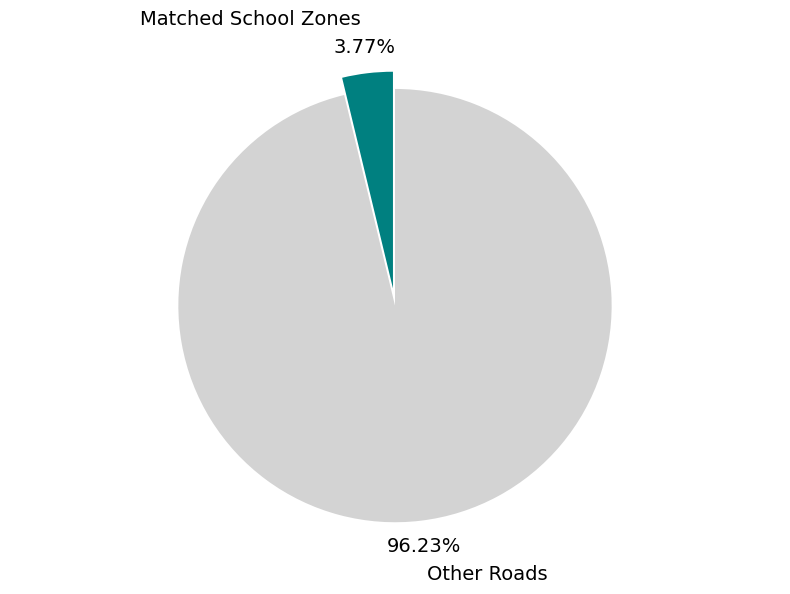

In [ ]:
# School Zone Crash Records - Pie Chart

matched = len(unique_school_crashes)
other = len(crash_df) - matched

labels = ['Matched School Zones', 'Other Roads']
values = [matched, other]

plt.figure(figsize=(8, 6))

plt.pie(
    values,
    labels=labels,
    autopct='%1.2f%%',
    startangle=90,
    colors=['teal', 'lightgrey'],
    explode=(0.08, 0),
    pctdistance=1.12,
    labeldistance=1.25,
    textprops={'fontsize': 14}
)

plt.axis('equal')
plt.tight_layout()
plt.show()

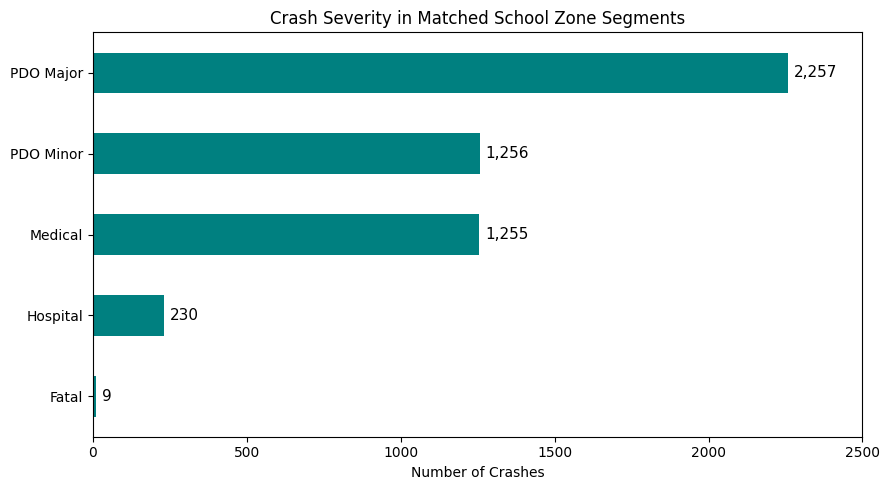

In [ ]:
# Crash Severity in Matched School Zone Segments

severity_counts = unique_school_crashes['SEVERITY'].value_counts()

plt.figure(figsize=(9, 5))

severity_counts.sort_values().plot(
    kind='barh',
    color='teal'
)

plt.title('Crash Severity in Matched School Zone Segments')
plt.xlabel('Number of Crashes')
plt.ylabel('')

for i, value in enumerate(severity_counts.sort_values()):
    plt.text(value + 20, i, f'{value:,}', va='center', fontsize=11)

plt.xlim(0, 2500)
plt.tight_layout()
plt.show()

## 6. Time Based Crash Analysis
Crash times are checked for valid hour/minute values before deriving hourly patterns. Missing times are acknowledged. The analysis then examines hours, weekdays and weekends to identify when recorded crashes are concentrated.

In [ ]:
# Investigating crash time format in matched school zones
print("CRASH TIME DATA TYPE")
print(unique_school_crashes['CRASH_TIME'].dtype)
print("\nFIRST 10 CRASH TIME VALUES")
print(unique_school_crashes['CRASH_TIME'].head(10))

CRASH TIME DATA TYPE
float64

FIRST 10 CRASH TIME VALUES
15     1155.0
53     1510.0
63      850.0
79     1505.0
93      825.0
100    1350.0
238    1400.0
279    1800.0
280     845.0
329    1600.0
Name: CRASH_TIME, dtype: float64


In [ ]:
# Checking invalid crash time values
print("CRASH TIME VALIDATION")
crash_time = unique_school_crashes['CRASH_TIME'].dropna()
hours = crash_time // 100
minutes = crash_time % 100
invalid_times = crash_time[(hours > 23) | (minutes > 59) | (crash_time < 0) | (crash_time % 1 != 0)]
print("Valid time records:", len(crash_time) - len(invalid_times))
print("Invalid time records:", len(invalid_times))
print("Missing time records:",unique_school_crashes['CRASH_TIME'].isnull().sum())

CRASH TIME VALIDATION
Valid time records: 4981
Invalid time records: 0
Missing time records: 26


HOURLY CRASH DISTRIBUTION
HOUR
0.0      29
1.0      18
2.0      17
3.0       7
4.0      11
5.0      44
6.0     106
7.0     223
8.0     666
9.0     235
10.0    227
11.0    264
12.0    263
13.0    250
14.0    415
15.0    708
16.0    440
17.0    384
18.0    261
19.0    158
20.0    100
21.0     69
22.0     53
23.0     33
Name: count, dtype: int64


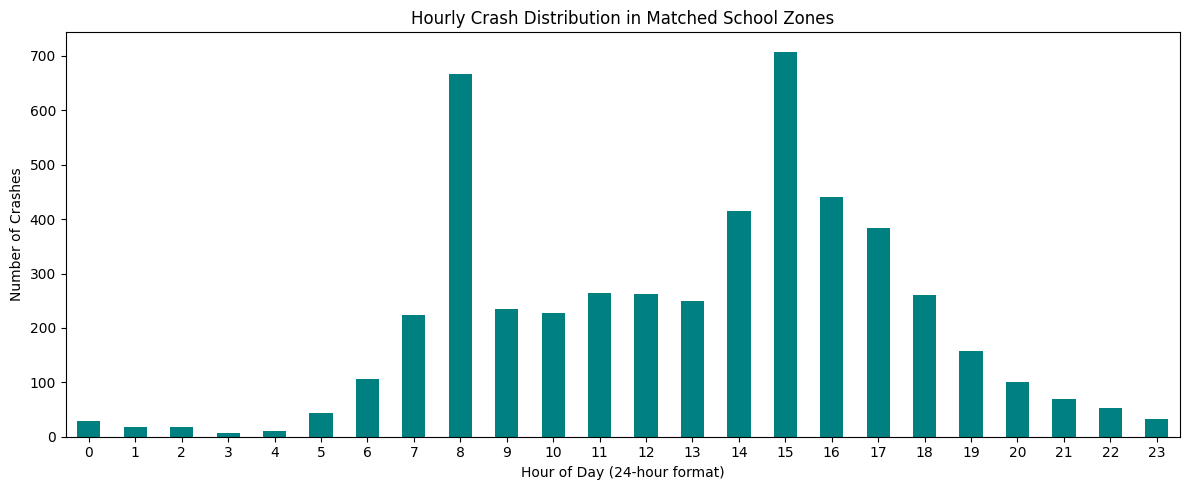

In [ ]:
# Hourly crash distribution in matched school zones
hourly_crashes = unique_school_crashes.copy()
hourly_crashes['HOUR'] = hourly_crashes['CRASH_TIME'] // 100
print("HOURLY CRASH DISTRIBUTION")
print(hourly_crashes['HOUR'].value_counts().sort_index())
plt.figure(figsize=(12, 5))
hourly_crashes['HOUR'].value_counts().sort_index().plot(kind='bar', color='teal')
plt.title('Hourly Crash Distribution in Matched School Zones')
plt.xlabel('Hour of Day (24-hour format)')
plt.ylabel('Number of Crashes')
plt.xticks(range(24), [str(i) for i in range(24)], rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Investigating crash distribution by day of the week
hourly_crashes['CRASH_DATE'] = pd.to_datetime(hourly_crashes['CRASH_DATE'], dayfirst=True, errors='coerce')
hourly_crashes['DAY_OF_WEEK'] = hourly_crashes['CRASH_DATE'].dt.day_name()
print("CRASH DISTRIBUTION BY DAY OF WEEK")
print(hourly_crashes['DAY_OF_WEEK'].value_counts())

CRASH DISTRIBUTION BY DAY OF WEEK
DAY_OF_WEEK
Wednesday    857
Tuesday      830
Thursday     817
Friday       814
Monday       784
Saturday     497
Sunday       408
Name: count, dtype: int64


In [ ]:
# Create date and time features

unique_school_crashes = unique_school_crashes.copy()

unique_school_crashes['CRASH_DATE'] = pd.to_datetime(
    unique_school_crashes['CRASH_DATE'],
    dayfirst=True,
    errors='coerce'
)

unique_school_crashes['DAY_OF_WEEK'] = unique_school_crashes['CRASH_DATE'].dt.day_name()

# Extract hour from HHMM crash time

unique_school_crashes['HOUR'] = (
    unique_school_crashes['CRASH_TIME'] // 100
)

# Check the results
print(unique_school_crashes[['CRASH_DATE', 'CRASH_TIME', 'DAY_OF_WEEK', 'HOUR']].head(10))

    CRASH_DATE  CRASH_TIME DAY_OF_WEEK  HOUR
15  2024-07-04      1155.0    Thursday  11.0
53  2024-07-30      1510.0     Tuesday  15.0
63  2024-08-02       850.0      Friday   8.0
79  2024-07-26      1505.0      Friday  15.0
93  2024-07-30       825.0     Tuesday   8.0
100 2024-08-01      1350.0    Thursday  13.0
238 2024-07-28      1400.0      Sunday  14.0
279 2024-08-01      1800.0    Thursday  18.0
280 2024-07-30       845.0     Tuesday   8.0
329 2024-08-01      1600.0    Thursday  16.0


In [ ]:
# Comparing hourly crash patterns on weekdays and weekends

unique_school_crashes['DAY_TYPE'] = 'Weekday'

unique_school_crashes.loc[
    unique_school_crashes['DAY_OF_WEEK'].isin(['Saturday', 'Sunday']),
    'DAY_TYPE'
] = 'Weekend'

# Count crashes by hour and day type
hourly_comparison = pd.crosstab(
    unique_school_crashes['HOUR'],
    unique_school_crashes['DAY_TYPE']
)


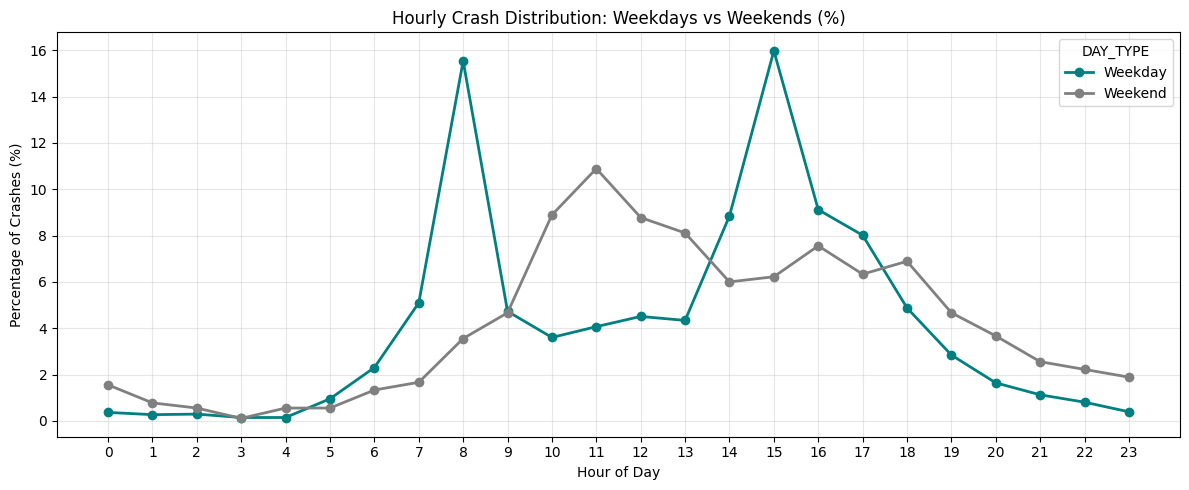

In [ ]:
# Comparing hourly crash percentages on weekdays and weekends

hourly_percentage = hourly_comparison.div(
    hourly_comparison.sum(axis=0), axis=1
) * 100

hourly_percentage.plot(
    kind='line',
    figsize=(12, 5),
    marker='o',
    color={'Weekday': 'teal', 'Weekend': 'grey'},
    linewidth=2
)

plt.title('Hourly Crash Distribution: Weekdays vs Weekends (%)')
plt.xlabel('Hour of Day')
plt.ylabel('Percentage of Crashes (%)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.1 Approximate School Travel Periods
Weekday crashes are filtered to 7:30–9:00 AM and 2:30–4:00 PM as approximate school travel windows. These are not verified active school zone periods: the calculation does not account for school holidays, public holidays, school specific schedules or historical changes.

In [ ]:
# Investigating weekday crashes during standard school zone hours
hourly_crashes['DAY_TYPE'] = 'Weekday'
hourly_crashes.loc[hourly_crashes['DAY_OF_WEEK'].isin(['Saturday', 'Sunday']), 'DAY_TYPE'] = 'Weekend'

weekday_crashes = hourly_crashes[hourly_crashes['DAY_TYPE'] == 'Weekday']
morning_crashes = weekday_crashes[(weekday_crashes['CRASH_TIME'] >= 730) & (weekday_crashes['CRASH_TIME'] < 900)]
afternoon_crashes = weekday_crashes[(weekday_crashes['CRASH_TIME'] >= 1430) & (weekday_crashes['CRASH_TIME'] < 1600)]
print("WEEKDAY CRASHES DURING STANDARD SCHOOL ZONE HOURS")
print("Morning (7:30–9:00 AM):", len(morning_crashes))
print("Afternoon (2:30–4:00 PM):", len(afternoon_crashes))
print("Total:", len(morning_crashes) + len(afternoon_crashes))

WEEKDAY CRASHES DURING STANDARD SCHOOL ZONE HOURS
Morning (7:30–9:00 AM): 777
Afternoon (2:30–4:00 PM): 907
Total: 1684


In [ ]:
# Comparing crash severity during morning and afternoon school zone hours
print("MORNING CRASH SEVERITY")
print(morning_crashes['SEVERITY'].value_counts())
print("\nAFTERNOON CRASH SEVERITY")
print(afternoon_crashes['SEVERITY'].value_counts())

MORNING CRASH SEVERITY
SEVERITY
PDO Major    343
PDO Minor    228
Medical      186
Hospital      19
Fatal          1
Name: count, dtype: int64

AFTERNOON CRASH SEVERITY
SEVERITY
PDO Major    389
PDO Minor    267
Medical      215
Hospital      36
Name: count, dtype: int64


In [ ]:
# Comparing morning and afternoon crash severity percentages
severity_percentages = pd.DataFrame({'Morning (%)': morning_crashes['SEVERITY'].value_counts(normalize=True) * 100,
'Afternoon (%)': afternoon_crashes['SEVERITY'].value_counts(normalize=True) * 100}).fillna(0)
print("CRASH SEVERITY PERCENTAGE COMPARISON")
display(severity_percentages.round(2))


CRASH SEVERITY PERCENTAGE COMPARISON


,Morning (%),Afternoon (%)
SEVERITY,,
Fatal,0.13,0.00
Hospital,2.45,3.97
Medical,23.94,23.70
PDO Major,44.14,42.89
PDO Minor,29.34,29.44


### 6.2 Pedestrian Involved Crashes
Pedestrian involved crashes are identified using the recorded pedestrian count. Morning and afternoon severity distributions are compared using percentages as well as counts, while avoiding causal conclusions.

In [ ]:
# Investigating pedestrian crashes during school travel periods
morning_pedestrian = morning_crashes[morning_crashes['TOTAL_PEDESTRIANS_INVOLVED'] > 0]
afternoon_pedestrian = afternoon_crashes[afternoon_crashes['TOTAL_PEDESTRIANS_INVOLVED'] > 0]
print("PEDESTRIAN-INVOLVED CRASHES")
print("Morning:", len(morning_pedestrian))
print("Afternoon:", len(afternoon_pedestrian))

PEDESTRIAN-INVOLVED CRASHES
Morning: 47
Afternoon: 64


In [ ]:
# Investigating pedestrian crash severity
print("MORNING PEDESTRIAN CRASH SEVERITY")
print(morning_pedestrian['SEVERITY'].value_counts())
print("\nAFTERNOON PEDESTRIAN CRASH SEVERITY")
print(afternoon_pedestrian['SEVERITY'].value_counts())

MORNING PEDESTRIAN CRASH SEVERITY
SEVERITY
Medical      29
PDO Minor    11
Hospital      6
PDO Major     1
Name: count, dtype: int64

AFTERNOON PEDESTRIAN CRASH SEVERITY
SEVERITY
Medical      34
Hospital     14
PDO Minor    14
PDO Major     2
Name: count, dtype: int64


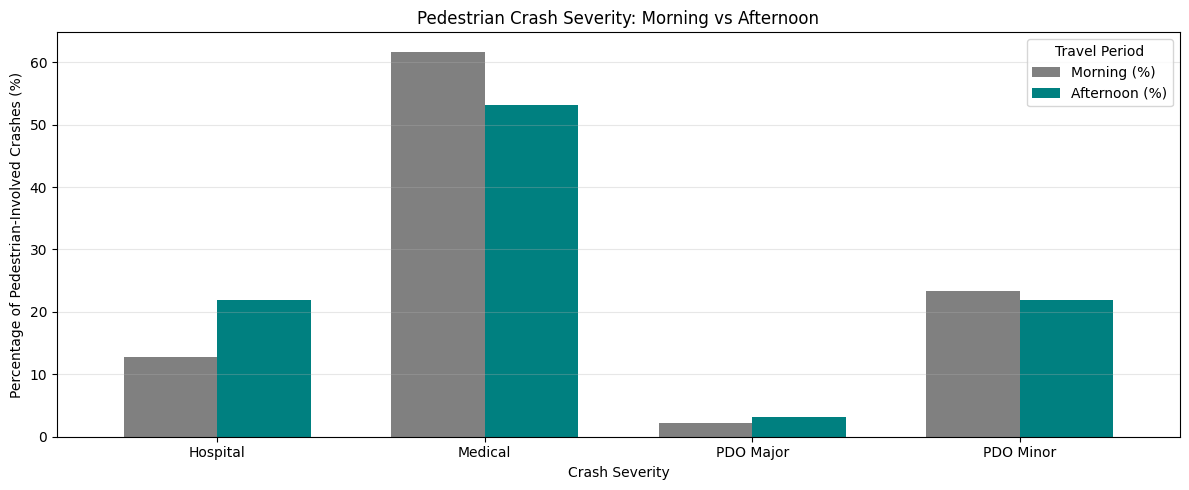

In [ ]:
# Comparing pedestrian crash severity percentages
pedestrian_severity = pd.DataFrame({
    'Morning (%)': morning_pedestrian['SEVERITY'].value_counts(normalize=True) * 100,
    'Afternoon (%)': afternoon_pedestrian['SEVERITY'].value_counts(normalize=True) * 100})
pedestrian_severity = pedestrian_severity.fillna(0)
# Pedestrian Crash Severity: Morning vs Afternoon

pedestrian_severity.plot(
    kind='bar',
    figsize=(12, 5),
    color=['grey', 'teal'],
    width=0.7
)

plt.title('Pedestrian Crash Severity: Morning vs Afternoon')
plt.xlabel('Crash Severity')
plt.ylabel('Percentage of Pedestrian-Involved Crashes (%)')
plt.xticks(rotation=0)
plt.legend(title='Travel Period')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3 Annual and Monthly Patterns
Yearly and monthly totals describe changes in recorded geographically matched crashes. These raw counts do not adjust for traffic volume, population, reporting practices or the number of active school days; consequently they should not be treated as exposure adjusted risk rates.

MONTHLY CRASH DISTRIBUTION
MONTH
1     284
2     439
3     452
4     335
5     495
6     490
7     383
8     471
9     428
10    403
11    460
12    367
Name: count, dtype: int64


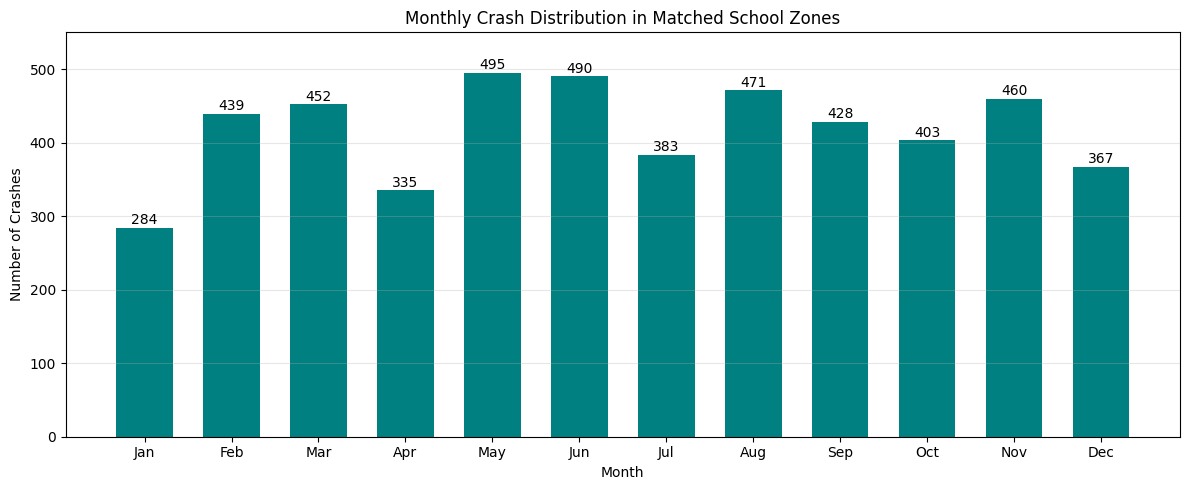

In [ ]:
# Investigating monthly crash distribution
hourly_crashes['MONTH'] = hourly_crashes['CRASH_DATE'].dt.month
monthly_crashes = hourly_crashes['MONTH'].value_counts().sort_index()
print("MONTHLY CRASH DISTRIBUTION")
print(monthly_crashes)

# Monthly Crash Distribution

month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_counts = monthly_crashes.reindex(range(1, 13), fill_value=0)

plt.figure(figsize=(12, 5))

bars = plt.bar(
    month_names,
    monthly_counts.values,
    color='teal',
    width=0.65
)

# Display crash counts above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        str(int(height)),
        ha='center'
    )

plt.title('Monthly Crash Distribution in Matched School Zones')
plt.xlabel('Month')
plt.ylabel('Number of Crashes')
plt.ylim(0, 550)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Multivariate Analysis: PCA
Six numerical road user involvement counts are selected to explore common variation across matched crashes. The same original non-negative counts can later be used for NMF, but PCA first requires standardisation because the variables have different distributions and frequencies.

In [ ]:
# Identifying numerical features for PCA
print("NUMERICAL COLUMNS AVAILABLE FOR ANALYSIS")
display(unique_school_crashes.select_dtypes(include='number').columns)

NUMERICAL COLUMNS AVAILABLE FOR ANALYSIS


Index(['X', 'Y', 'ACC_ID', 'SLK', 'INTERSECTION_NO', 'LONGITUDE', 'LATITUDE',
       'CRASH_TIME', 'TOTAL_BIKE_INVOLVED', 'TOTAL_TRUCK_INVOLVED',
       'TOTAL_HEAVY_TRUCK_INVOLVED', 'TOTAL_MOTOR_CYCLE_INVOLVED',
       'TOTAL_OTHER_VEHICLES_INVOLVED', 'TOTAL_PEDESTRIANS_INVOLVED',
       'OBJECTID_x', 'START_SLK', 'END_SLK', 'START_TRUE_DIST',
       'END_TRUE_DIST', 'RA_NO', 'LG_NO', 'ROUTE_NE_ID', 'OBJECTID_y',
       'GEOLOCSTLength', 'HOUR'],
      dtype='object')

In [ ]:
# Selecting road user involvement features for PCA
features = ['TOTAL_BIKE_INVOLVED','TOTAL_TRUCK_INVOLVED','TOTAL_HEAVY_TRUCK_INVOLVED','TOTAL_MOTOR_CYCLE_INVOLVED','TOTAL_OTHER_VEHICLES_INVOLVED', 'TOTAL_PEDESTRIANS_INVOLVED']
feature_df = unique_school_crashes[features].copy()
print("SELECTED FEATURES FOR PCA")
display(feature_df.head(10))

SELECTED FEATURES FOR PCA


,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED
15,0,0,0,1,0,0
53,0,0,0,0,2,0
63,0,0,0,0,2,0
79,0,0,0,0,2,0
93,0,0,0,0,2,0
100,0,0,0,0,2,0
238,0,0,0,0,2,0
279,0,0,0,0,1,0
280,0,0,0,0,2,0
329,0,0,0,0,2,0


In [ ]:
# Examining selected feature distributions
print("ROAD-USER INVOLVEMENT FEATURE SUMMARY")
display(feature_df.describe())

ROAD-USER INVOLVEMENT FEATURE SUMMARY


,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED
count,5007.000000,5007.000000,5007.000000,5007.000000,5007.000000,5007.000000
mean,0.033952,0.021370,0.003595,0.032554,1.615738,0.044538
std,0.185484,0.148715,0.059856,0.183026,0.670222,0.236107
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
max,2.000000,2.000000,1.000000,2.000000,6.000000,4.000000


In [ ]:
# Counting crashes with involvement in each road-user category
print("CRASHES WITH ROAD USER INVOLVEMENT")
involvement_counts = (feature_df > 0).sum()
display(involvement_counts)

CRASHES WITH ROAD USER INVOLVEMENT


,0
TOTAL_BIKE_INVOLVED,166
TOTAL_TRUCK_INVOLVED,104
TOTAL_HEAVY_TRUCK_INVOLVED,18
TOTAL_MOTOR_CYCLE_INVOLVED,158
TOTAL_OTHER_VEHICLES_INVOLVED,4661
TOTAL_PEDESTRIANS_INVOLVED,194


### 7.1 Correlation and Standardisation
Correlations show whether involvement counts tend to vary together. Standardisation puts features on a comparable scale for PCA; rare involvement categories can still produce extreme standardised values.

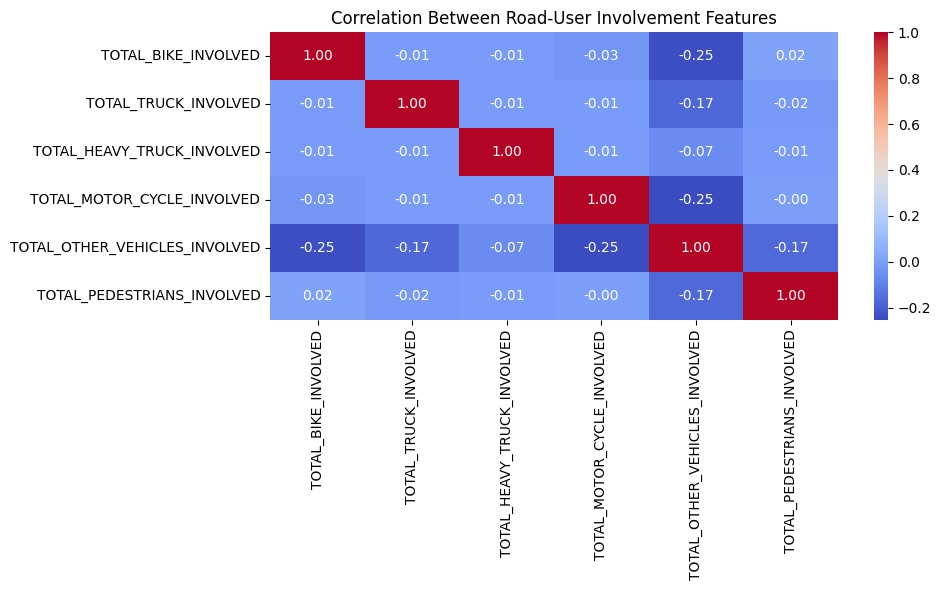

In [ ]:
# Investigating correlations between road-user involvement features
feature_correlation = feature_df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(feature_correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Road-User Involvement Features')
plt.tight_layout()
plt.show()

In [ ]:
# Standardising road-user involvement features for PCA
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
pca_data = scaler.fit_transform(feature_df)
print("STANDARDISED DATA FOR PCA")
print(pca_data[:5])

STANDARDISED DATA FOR PCA
[[-0.18306619 -0.14371261 -0.06006611  5.28636392 -2.41099279 -0.18865181]
 [-0.18306619 -0.14371261 -0.06006611 -0.17788549  0.57339309 -0.18865181]
 [-0.18306619 -0.14371261 -0.06006611 -0.17788549  0.57339309 -0.18865181]
 [-0.18306619 -0.14371261 -0.06006611 -0.17788549  0.57339309 -0.18865181]
 [-0.18306619 -0.14371261 -0.06006611 -0.17788549  0.57339309 -0.18865181]]


In [ ]:
# Checking the mean and standard deviation after standardisation

print("FEATURE MEANS")
print(pca_data.mean(axis=0).round(2))

print("\nFEATURE STANDARD DEVIATIONS")
print(pca_data.std(axis=0).round(2))

FEATURE MEANS
[-0. -0. -0. -0.  0. -0.]

FEATURE STANDARD DEVIATIONS
[1. 1. 1. 1. 1. 1.]


### 7.2 Explained Variance
PCA transforms the six standardised features into orthogonal components. The explained variance ratios indicate how much of the feature variation, not crash severity, each component captures. In this dataset PC1 explains 23.58% and PC2 17.28%; approximately five components are needed to retain 90%.

In [ ]:
# Applying PCA to standardised road user involvement features
from sklearn.decomposition import PCA
pca = PCA()
pca_result = pca.fit_transform(pca_data)
print("PCA RESULT - FIRST 5 CRASH RECORDS")
print(pca_result[:5])
print("\nNUMBER OF PRINCIPAL COMPONENTS")
print(pca.n_components_)

PCA RESULT - FIRST 5 CRASH RECORDS
[[-3.67313196  3.65241264 -2.08973754 -0.08641918 -1.57121215  0.42035503]
 [ 0.65547046  0.00545073 -0.00907491 -0.01918233 -0.04855431  0.14597194]
 [ 0.65547046  0.00545073 -0.00907491 -0.01918233 -0.04855431  0.14597194]
 [ 0.65547046  0.00545073 -0.00907491 -0.01918233 -0.04855431  0.14597194]
 [ 0.65547046  0.00545073 -0.00907491 -0.01918233 -0.04855431  0.14597194]]

NUMBER OF PRINCIPAL COMPONENTS
6


In [ ]:
# Examining explained variance for each principal component
explained_variance = pca.explained_variance_ratio_ * 100
print("EXPLAINED VARIANCE BY PRINCIPAL COMPONENT")
for i, variance in enumerate(explained_variance):
    print("PC", i + 1, ":", round(variance, 2), "%")

EXPLAINED VARIANCE BY PRINCIPAL COMPONENT
PC 1 : 23.58 %
PC 2 : 17.28 %
PC 3 : 16.94 %
PC 4 : 16.76 %
PC 5 : 16.29 %
PC 6 : 9.14 %


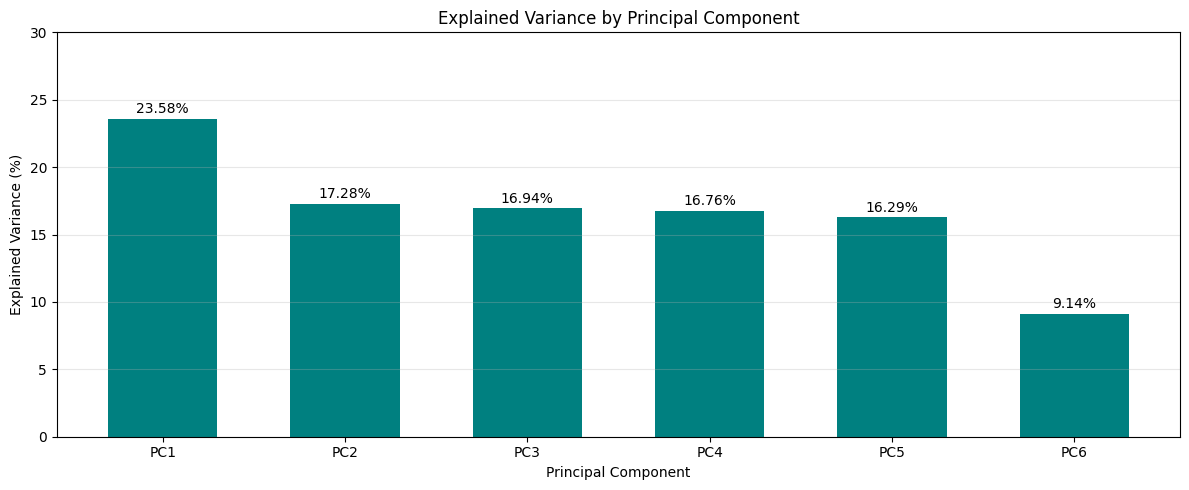

In [ ]:
# Plotting explained variance by principal component

component_names = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']

plt.figure(figsize=(12, 5))

bars = plt.bar(component_names, explained_variance, color='teal', width=0.6)

# Display percentage above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.4,str(round(height, 2)) + '%', ha='center')

plt.title('Explained Variance by Principal Component')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.ylim(0, 30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

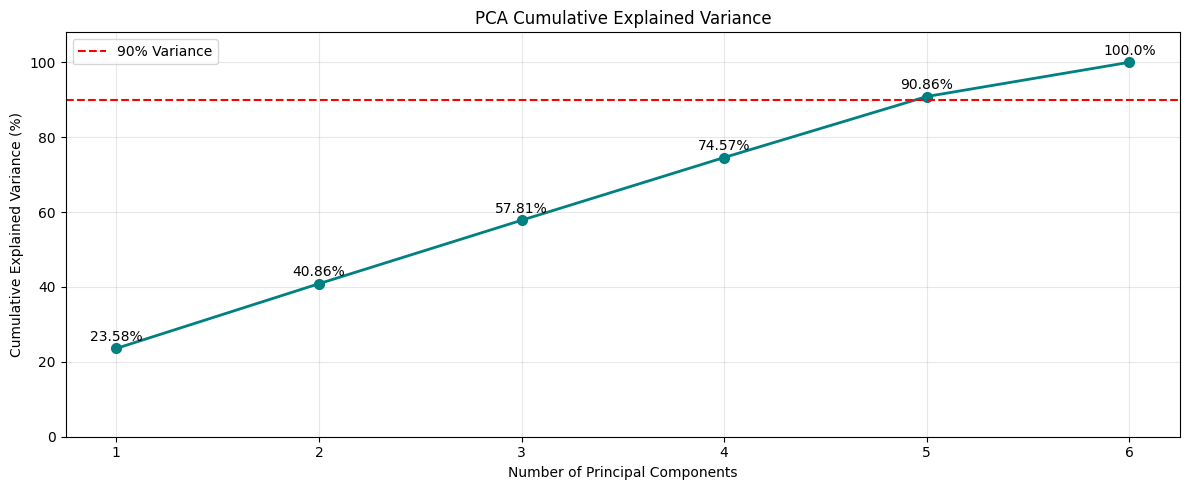

In [ ]:
# Visualising cumulative explained variance

cumulative_variance = explained_variance.cumsum()

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 7),
    cumulative_variance,
    color='teal',
    marker='o',
    linewidth=2,
    markersize=7
)

# 90% variance reference line
plt.axhline(
    y=90,
    color='red',
    linestyle='--',
    label='90% Variance'
)

# Add percentage labels
for i, variance in enumerate(cumulative_variance):
    plt.text(
        i + 1,
        variance + 2,
        str(round(variance, 2)) + '%',
        ha='center'
    )

plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.xticks(range(1, 7))
plt.ylim(0, 108)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3 Component Loadings
Loadings indicate how strongly each original feature contributes to each principal component. PC1 primarily contrasts other vehicle involvement with bicycle, motorcycle and pedestrian involvement. The direction of a component is arbitrary; interpretations should focus on relative patterns rather than positive or negative labels alone.

In [ ]:
# Investigating PCA component loadings
pca_loadings = pd.DataFrame(pca.components_, columns=features, index=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6'])
print("PCA COMPONENT LOADINGS")
display(pca_loadings.round(3))

PCA COMPONENT LOADINGS


,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED
PC1,-0.399,-0.261,-0.079,-0.398,0.721,-0.296
PC2,-0.643,0.240,0.085,0.654,-0.025,-0.307
PC3,0.119,0.782,0.175,-0.396,-0.028,-0.431
PC4,0.033,-0.282,0.954,-0.029,-0.031,-0.087
PC5,-0.494,0.312,0.170,-0.270,0.015,0.746
PC6,0.411,0.293,0.132,0.428,0.691,0.260


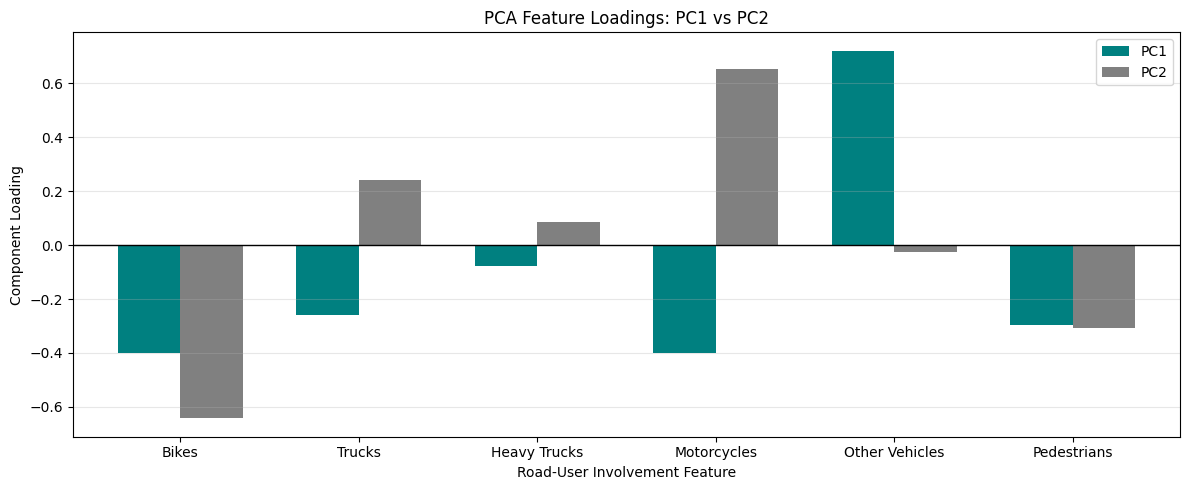

In [ ]:
# Visualising PCA component loadings

loading_features = ['Bikes', 'Trucks', 'Heavy Trucks','Motorcycles', 'Other Vehicles', 'Pedestrians']

loading_comparison = pca_loadings.loc[['PC1', 'PC2']].T

loading_comparison.index = loading_features

loading_comparison.plot(kind='bar', figsize=(12, 5), color=['teal', 'grey'], width=0.7)

plt.title('PCA Feature Loadings: PC1 vs PC2')
plt.xlabel('Road-User Involvement Feature')
plt.ylabel('Component Loading')
plt.xticks(rotation=0)
plt.axhline(0, color='black', linewidth=1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 7.4 PCA Scores and Visualisation
Each crash receives a score on each principal component. Because many crashes have identical involvement counts, multiple records can share the same PCA coordinates and overlap in scatter plots. The PC1–PC2 view captures only 40.86% of total feature variance.

In [ ]:
# Creating a table of PCA scores for each crash
pca_scores = pd.DataFrame(pca_result, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6'])
print("PCA SCORES FOR INDIVIDUAL CRASHES")
display(pca_scores.head(10))

PCA SCORES FOR INDIVIDUAL CRASHES


,PC1,PC2,PC3,PC4,PC5,PC6
0,-3.673132,3.652413,-2.089738,-0.086419,-1.571212,0.420355
1,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972
2,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972
3,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972
4,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972
5,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972
6,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972
7,-0.420254,0.042735,0.033111,0.027628,-0.071419,-0.885325
8,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972
9,0.655470,0.005451,-0.009075,-0.019182,-0.048554,0.145972


### 7.5 Exploratory Comparison with Severity
Crash severity is added after PCA for interpretation; it was not used to fit the components. The colour coded plot can reveal associations but cannot establish predictive performance, statistically significant separation or causality. Overplotting can hide many records.

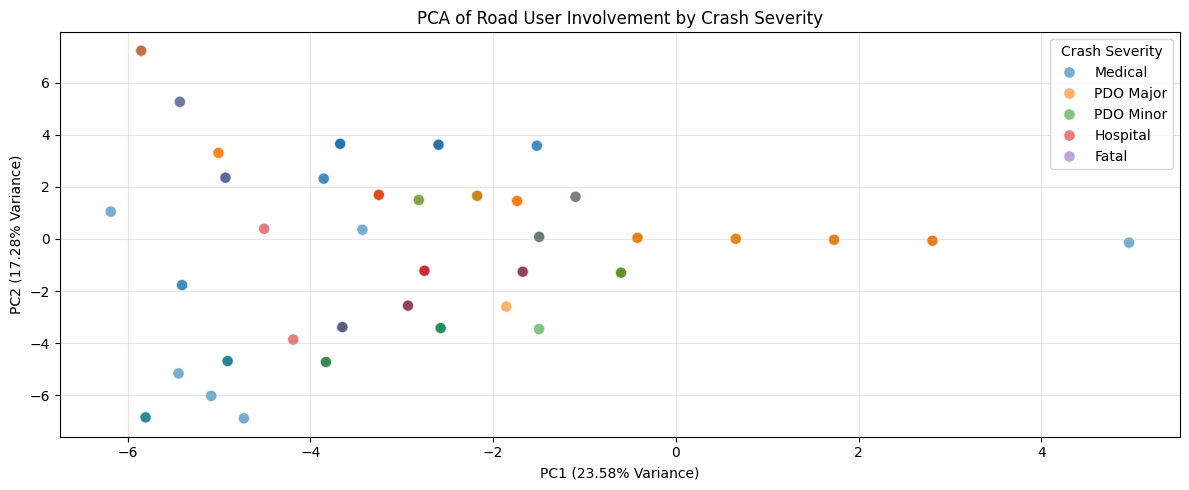

In [ ]:
# Comparing PCA components with crash severity

pca_scores['SEVERITY'] = unique_school_crashes['SEVERITY'].values

plt.figure(figsize=(12, 5))

sns.scatterplot( data=pca_scores, x='PC1', y='PC2', hue='SEVERITY', alpha=0.6,s=65)

plt.title('PCA of Road User Involvement by Crash Severity')
plt.xlabel('PC1 (23.58% Variance)')
plt.ylabel('PC2 (17.28% Variance)')
plt.legend(title='Crash Severity')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 7.6 Average Scores by Severity
Mean PC1 and PC2 scores summarise where severity groups fall in component space. Fatal and Hospital crashes have more negative mean PC1 scores than the PDO groups, but these averages do not show how much individual observations overlap.

In [ ]:
# Calculating average PCA scores by crash severity
severity_pca = pca_scores.groupby('SEVERITY')[['PC1', 'PC2']].mean()
print("AVERAGE PCA SCORES BY CRASH SEVERITY")
display(severity_pca.round(3))

AVERAGE PCA SCORES BY CRASH SEVERITY


,PC1,PC2
SEVERITY,,
Fatal,-1.078,-0.776
Hospital,-1.207,0.043
Medical,-0.361,-0.150
PDO Major,0.300,0.096
PDO Minor,0.051,-0.025


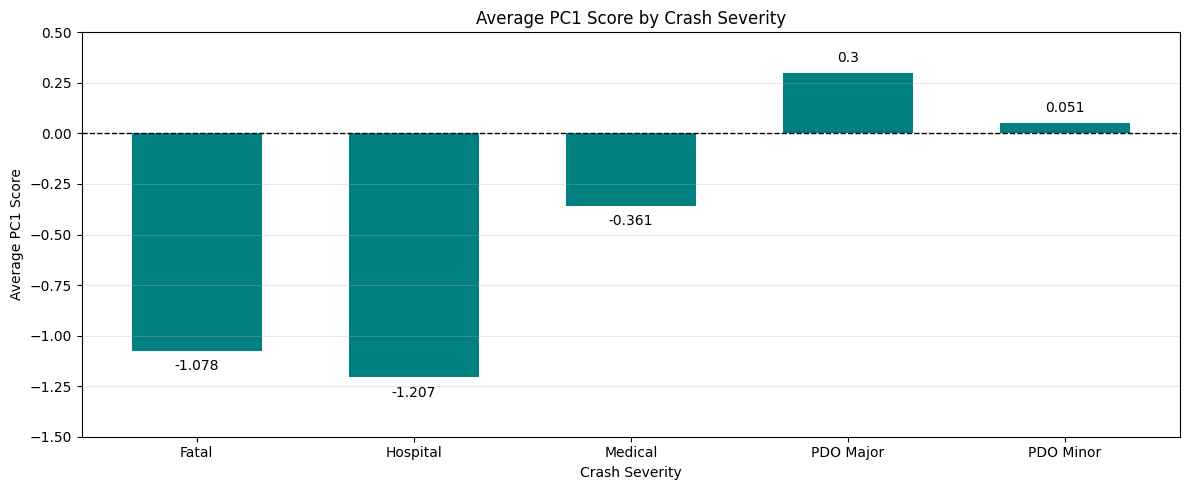

In [ ]:
# Comparing average PC1 scores by crash severity

plt.figure(figsize=(12, 5))

bars = plt.bar( severity_pca.index, severity_pca['PC1'],color='teal',width=0.6)

# Add value labels
for bar in bars:
    height = bar.get_height()

    if height >= 0:
        label_position = height + 0.04
        vertical_alignment = 'bottom'
    else:
        label_position = height - 0.04
        vertical_alignment = 'top'

    plt.text(bar.get_x() + bar.get_width() / 2,label_position,str(round(height, 3)),ha='center', va=vertical_alignment)

plt.axhline(0, color='black', linestyle='--', linewidth=1)

plt.title('Average PC1 Score by Crash Severity')
plt.xlabel('Crash Severity')
plt.ylabel('Average PC1 Score')
plt.ylim(-1.5, 0.5)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 7.7 Within Group Variation and PCA Findings
Standard deviations and group sizes help contextualise the mean differences. Hospital crashes show substantial PC1 variation, and only nine Fatal crashes are available, so that group's mean is unstable. Overall, PCA reveals road user involvement contrasts but offers limited dimensionality reduction and no clear severity group separation in the first two components.



In [ ]:
# Calculating variation in PC1 scores by crash severity
pca_variation = pca_scores.groupby('SEVERITY')['PC1'].agg(['count', 'mean', 'std'])
print("PC1 SCORE VARIATION BY CRASH SEVERITY")
display(pca_variation.round(3))

PC1 SCORE VARIATION BY CRASH SEVERITY


,count,mean,std
SEVERITY,,,
Fatal,9,-1.078,1.395
Hospital,230,-1.207,1.596
Medical,1255,-0.361,1.506
PDO Major,2257,0.300,0.851
PDO Minor,1256,0.051,1.016


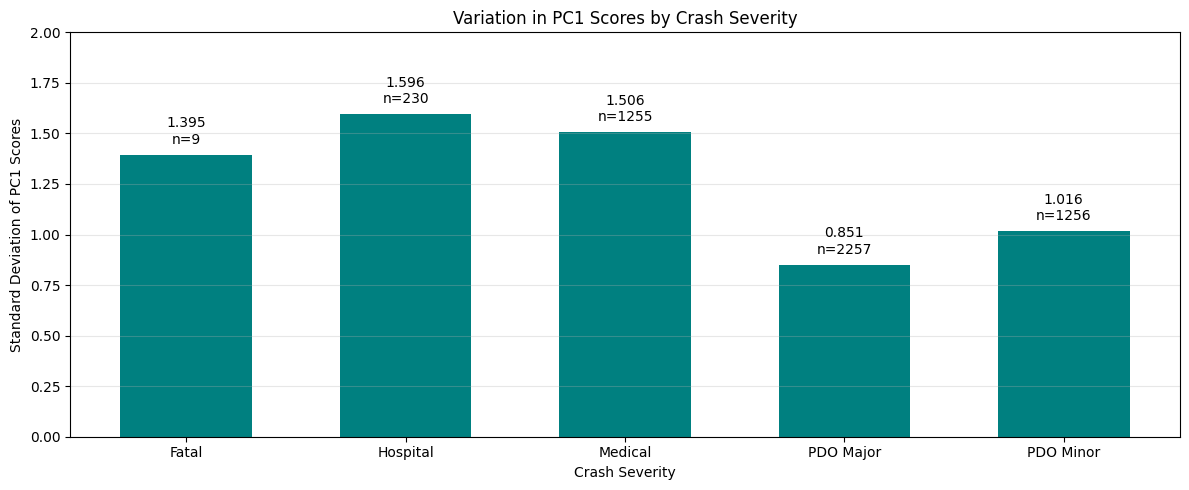

In [ ]:
# Visualising variation in PC1 scores by crash severity

plt.figure(figsize=(12, 5))

bars = plt.bar(
    pca_variation.index,
    pca_variation['std'],
    color='teal',
    width=0.6
)

# Add standard deviation and crash count above each bar
for bar, count in zip(bars, pca_variation['count']):
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.04,
        f'{height:.3f}\nn={count}',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Variation in PC1 Scores by Crash Severity')
plt.xlabel('Crash Severity')
plt.ylabel('Standard Deviation of PC1 Scores')
plt.ylim(0, 2)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.cluster import KMeans

# Select the first 5 principal components
X_cluster = pca_scores[['PC1', 'PC2', 'PC3', 'PC4', 'PC5']]

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Assign a cluster to each crash
cluster_labels = kmeans.fit_predict(X_cluster)

# Store the results
pca_scores['Cluster'] = cluster_labels

# Count crashes in each cluster
print("Crashes in each cluster:")
print(pca_scores['Cluster'].value_counts().sort_index())

# Check how many unique PCA feature combinations exist
print("\nUnique PCA score combinations:")
print(X_cluster.drop_duplicates().shape[0])


Crashes in each cluster:
Cluster
0    4182
1     807
2      18
Name: count, dtype: int64

Unique PCA score combinations:
38


In [ ]:

# Examine the original features for each cluster

cluster_features = feature_df.copy()

# Add cluster labels
cluster_features['Cluster'] = cluster_labels

# Average feature values in each cluster
print("Average road-user involvement by cluster:")
print(cluster_features.groupby('Cluster').mean().round(3))

# Number of unique feature combinations
print("\nUnique feature combinations by cluster:")
print(cluster_features.groupby('Cluster').apply(
    lambda group: group.drop(columns='Cluster').drop_duplicates().shape[0]
))


Average road-user involvement by cluster:
         TOTAL_BIKE_INVOLVED  TOTAL_TRUCK_INVOLVED  \
Cluster                                              
0                      0.000                 0.000   
1                      0.211                 0.133   
2                      0.000                 0.000   

         TOTAL_HEAVY_TRUCK_INVOLVED  TOTAL_MOTOR_CYCLE_INVOLVED  \
Cluster                                                           
0                               0.0                       0.000   
1                               0.0                       0.202   
2                               1.0                       0.000   

         TOTAL_OTHER_VEHICLES_INVOLVED  TOTAL_PEDESTRIANS_INVOLVED  
Cluster                                                             
0                                1.818                       0.004  
1                                0.582                       0.255  
2                                0.889                       0.000  

Uniqu

/tmp/ipykernel_669/753565226.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(cluster_features.groupby('Cluster').apply(


In [ ]:

# Compare crash severity across PCA clusters

cluster_severity = pd.crosstab(
    pca_scores['Cluster'],
    pca_scores['SEVERITY'],
    normalize='index'
) * 100

print("CRASH SEVERITY BY PCA CLUSTER (%)")
display(cluster_severity.round(2))

# Show the number of crashes in each cluster
print("\nNUMBER OF CRASHES BY CLUSTER")
print(pca_scores['Cluster'].value_counts().sort_index())


CRASH SEVERITY BY PCA CLUSTER (%)


SEVERITY,Fatal,Hospital,Medical,PDO Major,PDO Minor
Cluster,,,,,
0,0.14,2.53,21.09,49.98,26.26
1,0.37,15.37,45.97,19.33,18.96
2,0.00,0.00,11.11,61.11,27.78



NUMBER OF CRASHES BY CLUSTER
Cluster
0    4182
1     807
2      18
Name: count, dtype: int64


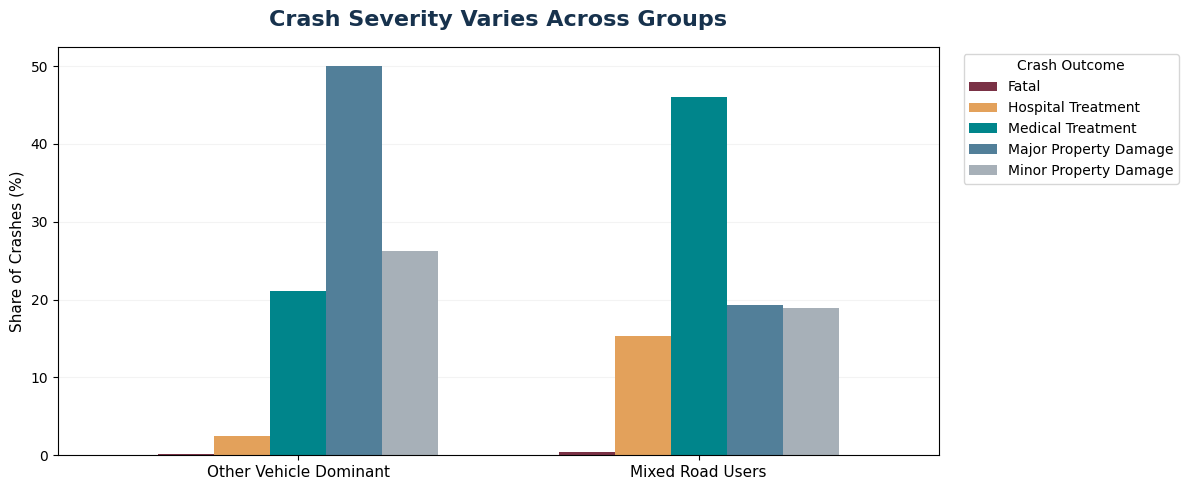

In [ ]:

# Compare crash severity in the two main PCA clusters

severity_chart = cluster_severity.loc[[0, 1]].copy()

# Stakeholder-friendly labels
severity_chart.index = ['Other Vehicle Dominant', 'Mixed Road Users']

severity_chart = severity_chart.rename(columns={
    'Fatal': 'Fatal',
    'Hospital': 'Hospital Treatment',
    'Medical': 'Medical Treatment',
    'PDO Major': 'Major Property Damage',
    'PDO Minor': 'Minor Property Damage'
})

# Presentation theme colours
colors = ['#7A3145', '#E3A15B', '#00858B', '#527F99', '#A7B0B8']

severity_chart.plot(
    kind='bar',
    figsize=(12, 5),
    color=colors,
    width=0.7
)

plt.title('Crash Severity Varies Across Groups',
          fontsize=16, fontweight='bold', color='#17324D', pad=15)

plt.xlabel('')
plt.ylabel('Share of Crashes (%)', fontsize=11)

plt.xticks(rotation=0, fontsize=11)
plt.legend(title='Crash Outcome', bbox_to_anchor=(1.02, 1),
           loc='upper left')

plt.grid(axis='y', alpha=0.15)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()


In [ ]:

# K-Means clustering on the original standardised features (no PCA)

# K-Means on original standardised features
kmeans_original = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

original_labels = kmeans_original.fit_predict(pca_data)

print("Cluster sizes without PCA:")
print(pd.Series(original_labels).value_counts().sort_index())


Cluster sizes without PCA:
0    4683
1     166
2     158
Name: count, dtype: int64


In [ ]:

# Compare clustering quality with and without PCA

from sklearn.metrics import silhouette_score

# Silhouette score using 5 PCA components
score_pca = silhouette_score(
    X_cluster,
    cluster_labels
)

# Silhouette score using original standardised features
score_original = silhouette_score(
    pca_data,
    original_labels
)

print("Silhouette Score Comparison")
print("PCA + K-Means:", round(score_pca, 3))
print("Original Features + K-Means:", round(score_original, 3))


Silhouette Score Comparison
PCA + K-Means: 0.728
Original Features + K-Means: 0.769


In [ ]:

# Test different numbers of clusters using PCA

cluster_numbers = [2, 3, 4, 5]
silhouette_scores = []

for k in cluster_numbers:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    score = silhouette_score(X_cluster, labels)
    silhouette_scores.append(score)

# Display results
for i in range(len(cluster_numbers)):
    print(
        "Clusters:", cluster_numbers[i],
        "| Silhouette Score:",
        round(silhouette_scores[i], 3)
    )


Clusters: 2 | Silhouette Score: 0.722
Clusters: 3 | Silhouette Score: 0.728
Clusters: 4 | Silhouette Score: 0.751
Clusters: 5 | Silhouette Score: 0.842


In [ ]:

# Examine the distribution of five PCA clusters

kmeans_5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_5 = kmeans_5.fit_predict(X_cluster)

# Count crashes in each cluster
cluster_counts_5 = pd.Series(labels_5).value_counts().sort_index()

print("Number of crashes in each cluster:")
print(cluster_counts_5)

print("\nPercentage of crashes in each cluster:")
print((cluster_counts_5 / len(labels_5) * 100).round(2))


Number of crashes in each cluster:
0     164
1    4565
2      18
3     104
4     156
Name: count, dtype: int64

Percentage of crashes in each cluster:
0     3.28
1    91.17
2     0.36
3     2.08
4     3.12
Name: count, dtype: float64


### PCA Application — Findings and Evaluation

PCA was applied to six standardised road-user involvement features from 5,007 crashes geographically matched to school speed-zone segments in Western Australia.

Five principal components retained **90.86% of the total variance**. K-Means clustering was then applied to the PCA-transformed data to investigate patterns in road-user involvement.

Using three clusters, the analysis identified a group of 807 crashes with a higher proportion of medical and hospital severity outcomes (**61.34%**) compared with the largest cluster of 4,182 crashes (**23.62%**).

However, PCA did not improve clustering separation compared with the original standardised features. The silhouette scores were **0.728 with PCA** and **0.769 without PCA**.

Testing five clusters increased the PCA-based silhouette score to **0.842**, but 91.17% of crashes belonged to one cluster.

**Conclusion:** PCA demonstrated a practical dimensionality-reduction and clustering workflow, but provided limited improvement for this dataset. The results are descriptive and do not establish causal relationships between road-user involvement and crash severity. Geographic matching also does not confirm that school-zone speed restrictions were active when crashes occurred.

## 8. Non-negative Matrix Factorisation (NMF)

Non-negative Matrix Factorisation (NMF) is used to identify underlying patterns in road user involvement across geographically matched school speed zone crashes.

Unlike PCA, NMF requires non-negative input values. Therefore, the original road-user involvement features will be used rather than the standardised PCA data.

The analysis will examine whether a smaller number of components can represent common patterns in the crash records.

### 8.1 Data Validation for NMF

Before applying NMF, the selected features are checked for missing and negative values to confirm that the dataset meets the basic requirements of the algorithm.


In [ ]:
# Checking selected features before applying NMF
print("NMF DATA VALIDATION")
print("Dataset shape:", feature_df.shape)
print("Missing values:", feature_df.isnull().sum().sum())
print("Negative values:", (feature_df < 0).sum().sum())

NMF DATA VALIDATION
Dataset shape: (5007, 6)
Missing values: 0
Negative values: 0


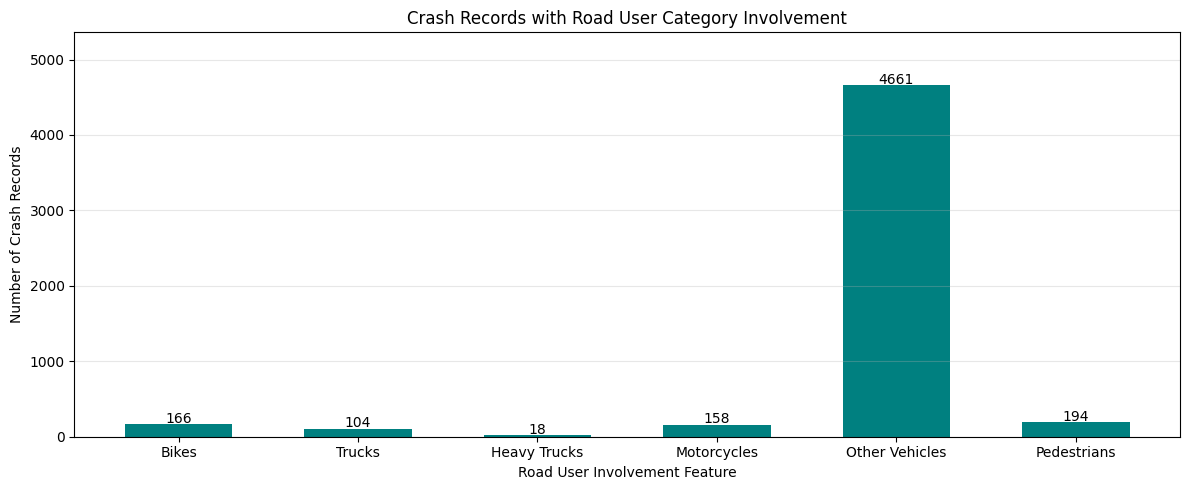

In [ ]:
# Visualising the six features selected for NMF

feature_names = ['Bikes', 'Trucks', 'Heavy Trucks','Motorcycles', 'Other Vehicles', 'Pedestrians']
feature_counts = (feature_df > 0).sum()
plt.figure(figsize=(12, 5))
bars = plt.bar( feature_names, feature_counts, color='teal', width=0.6)

for bar in bars:
    height = bar.get_height()
    plt.text( bar.get_x() + bar.get_width() / 2, height + 20, str(int(height)), ha='center')

plt.title('Crash Records with Road User Category Involvement')
plt.xlabel('Road User Involvement Feature')
plt.ylabel('Number of Crash Records')
plt.grid(axis='y', alpha=0.3)
plt.ylim(0, feature_counts.max() * 1.15)
plt.tight_layout()
plt.show()


### 8.2 Applying Non-negative Matrix Factorisation

NMF will be applied to the six road user involvement features to identify underlying patterns in geographically matched crash records.

The analysis will initially use two components to explore whether the original features can be represented by a smaller number of patterns.

The model will produce two matrices: one describing the component weights for individual crashes and another showing the contribution of each original feature to the components.


In [ ]:
# Applying NMF with two components
from sklearn.decomposition import NMF

nmf = NMF(n_components=2, init='nndsvda', random_state=42, max_iter=1000)
nmf_result = nmf.fit_transform(feature_df)

print("NMF COMPONENT WEIGHTS SHAPE")
print(nmf_result.shape)

print("NMF FEATURE COMPONENTS SHAPE")
print(nmf.components_.shape)

NMF COMPONENT WEIGHTS SHAPE
(5007, 2)
NMF FEATURE COMPONENTS SHAPE
(2, 6)



### 8.3 Interpreting NMF Components

The NMF component weights are examined to understand how the six road user involvement features contribute to each component.

Higher weights indicate a stronger contribution from a particular feature. By comparing these weights, we can identify the main road user involvement patterns represented by the two components.


In [ ]:
# Examining the contribution of each feature to the NMF components
nmf_components = pd.DataFrame(nmf.components_, columns=features, index=['Component 1', 'Component 2'])
print("NMF COMPONENT FEATURE WEIGHTS")
display(nmf_components.round(3))

NMF COMPONENT FEATURE WEIGHTS


,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED
Component 1,0.079,0.067,0.012,0.075,11.739,0.000
Component 2,0.343,0.019,0.000,0.190,0.073,4.151



**Findings — NMF Component Interpretation**

The two component NMF model identified distinct patterns in road user involvement.

Component 1 was dominated by other vehicle involvement, with a feature weight of 11.739. The remaining road user categories contributed relatively small weights.

Component 2 was dominated by pedestrian involvement, with a feature weight of 4.151. Bicycle and motorcycle involvement also contributed smaller weights.

These findings suggest that NMF separates the selected involvement features into vehicle dominated and pedestrian dominated patterns. However, the components do not establish crash causes or severity relationships.



### 8.4 Visualising NMF Component Weights

A heatmap is used to visualise the contribution of each road user involvement feature to the two NMF components.

The visualisation helps identify which features dominate each component and supports the interpretation of the underlying involvement patterns.


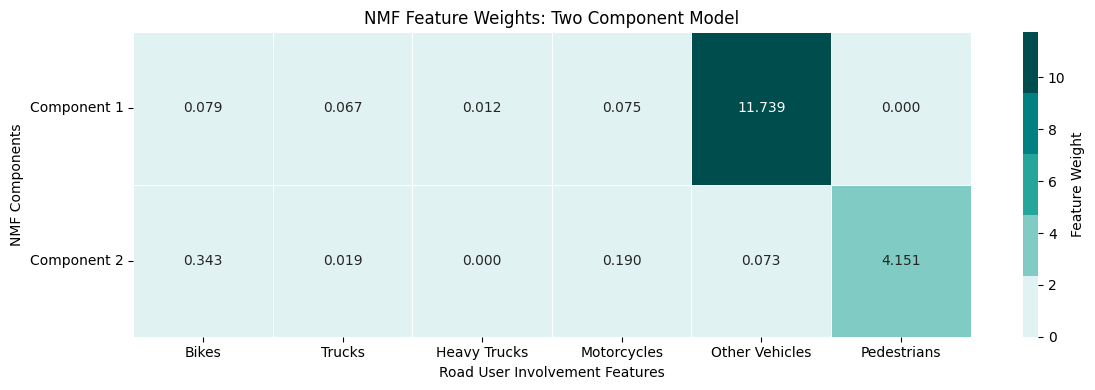

In [ ]:
# Visualising the two NMF component patterns

feature_labels = [
    'Bikes', 'Trucks', 'Heavy Trucks',
    'Motorcycles', 'Other Vehicles', 'Pedestrians'
]

plt.figure(figsize=(12, 4))

sns.heatmap(
    nmf_components,
    annot=True,
    fmt='.3f',
    cmap=sns.color_palette(['#E0F2F1', '#80CBC4', '#26A69A', '#008080', '#004D4D'],as_cmap=True),
    xticklabels=feature_labels,
    yticklabels=['Component 1', 'Component 2'],
    linewidths=0.5,
    cbar_kws={'label': 'Feature Weight'}
)

plt.title('NMF Feature Weights: Two Component Model')
plt.xlabel('Road User Involvement Features')
plt.ylabel('NMF Components')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### 8.5 Evaluating NMF Reconstruction Error

The reconstruction error is examined to evaluate how closely the two component NMF model represents the original road-user involvement data.

A lower reconstruction error indicates a closer approximation of the original dataset. However, the error must be interpreted in context, as it depends on the dataset and the number of components used.

This initial result will provide a baseline for comparing models with different numbers of components.


In [ ]:
# Evaluating reconstruction error for the two component NMF model
print("NMF RECONSTRUCTION ERROR")
print("Number of components:", nmf.n_components)
print("Reconstruction error:", round(nmf.reconstruction_err_, 3))

NMF RECONSTRUCTION ERROR
Number of components: 2
Reconstruction error: 21.88



### 8.6 Comparing NMF Component Numbers

NMF models with different numbers of components are compared to investigate how the number of components affects reconstruction error.

Models containing two to six components will be evaluated using the same road user involvement features.

The comparison will help determine whether additional components substantially improve the representation of the original data. A lower reconstruction error indicates a closer approximation, but more components also increase model complexity.


In [ ]:
# Comparing reconstruction errors for different NMF component numbers
component_numbers = [2, 3, 4, 5, 6]
reconstruction_errors = []

for n in component_numbers:
    model = NMF(n_components=n, init='nndsvda',random_state=42, max_iter=1000)
    model.fit(feature_df)
    reconstruction_errors.append(model.reconstruction_err_)

nmf_comparison = pd.DataFrame({'Components': component_numbers, 'Reconstruction Error': reconstruction_errors})

print("NMF RECONSTRUCTION ERROR COMPARISON")
display(nmf_comparison.round(3))

NMF RECONSTRUCTION ERROR COMPARISON


,Components,Reconstruction Error
0,2,21.880
1,3,17.391
2,4,11.422
3,5,4.248
4,6,0.274



### 8.7 Visualising NMF Reconstruction Error

A line graph is used to compare reconstruction errors across NMF models containing two to six components.

This visualisation helps examine whether increasing the number of components produces substantial improvements in reconstruction accuracy.

The aim is to balance a simpler representation of the data against the loss of information caused by reducing the number of components.


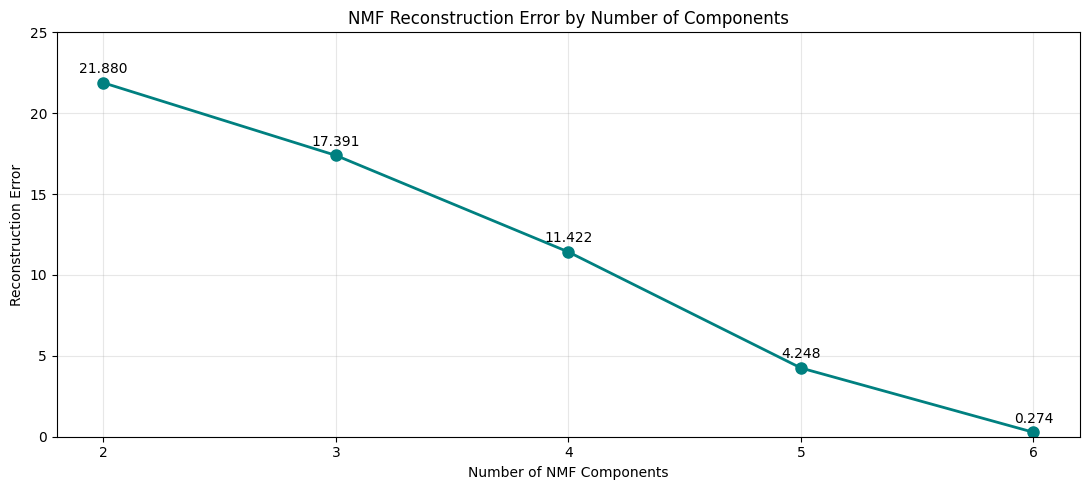

In [ ]:

# Visualising NMF reconstruction error
plt.figure(figsize=(11, 5))

plt.plot( nmf_comparison['Components'], nmf_comparison['Reconstruction Error'], color='teal', marker='o', linewidth=2, markersize=8)

# Display reconstruction error above each point
for x, y in zip(nmf_comparison['Components'],
                nmf_comparison['Reconstruction Error']):
    plt.text(x, y + 0.6, f'{y:.3f}', ha='center')

plt.title('NMF Reconstruction Error by Number of Components')
plt.xlabel('Number of NMF Components')
plt.ylabel('Reconstruction Error')
plt.xticks([2, 3, 4, 5, 6])
plt.ylim(0, 25)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### 8.8 Investigating a Three Component NMF Model

The reconstruction error comparison showed that increasing the number of components improves the approximation of the original dataset, without revealing a clear elbow point.

A three-component NMF model will now be examined to investigate whether an additional component identifies a distinct road-user involvement pattern.

The three component model will be compared with the earlier two-component model based on feature contributions and interpretability, rather than reconstruction error alone.


In [ ]:

# Applying NMF with three components
nmf_3 = NMF(n_components=3, init='nndsvda', random_state=42, max_iter=1000)
nmf_3_result = nmf_3.fit_transform(feature_df)

# Examining feature contributions
nmf_3_components = pd.DataFrame(nmf_3.components_, columns=features, index=['Component 1', 'Component 2', 'Component 3'])
print("THREE-COMPONENT NMF FEATURE WEIGHTS")
display(nmf_3_components.round(3))

THREE-COMPONENT NMF FEATURE WEIGHTS


,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED
Component 1,0.000,0.069,0.013,0.080,12.375,0.000
Component 2,0.000,0.016,0.000,0.224,0.141,4.802
Component 3,3.599,0.071,0.000,0.000,0.000,0.000



### 8.9 Visualising the Three Component NMF Model

A heatmap is used to visualise the feature contributions in the three component NMF model.

The analysis identified three dominant road user involvement patterns: other vehicles, pedestrians and bicycles.

The three component model provides a more detailed representation than the two component model while retaining fewer components than the original six features.


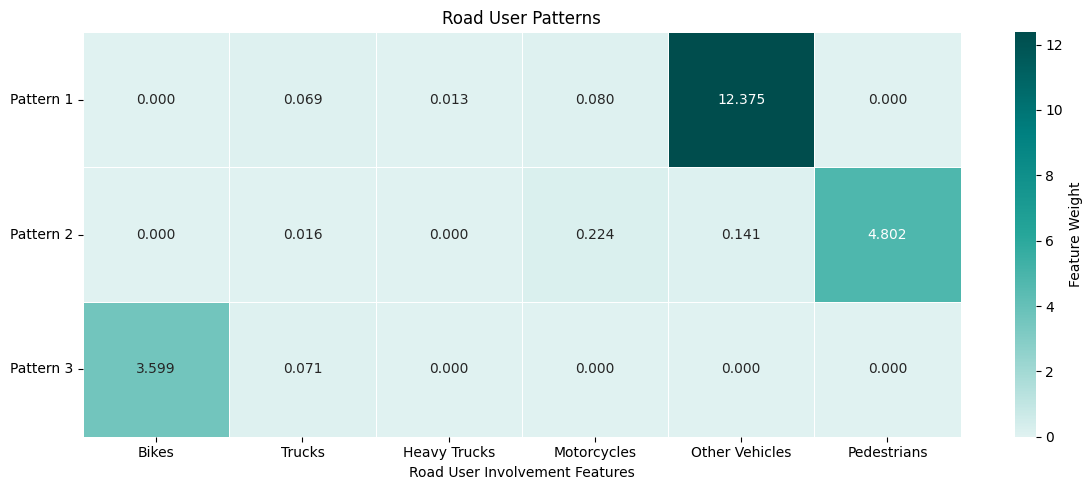

In [ ]:
# Visualising the three-component NMF model

from matplotlib.colors import LinearSegmentedColormap
teal_cmap = LinearSegmentedColormap.from_list('teal_palette',['#E0F2F1', '#80CBC4', '#26A69A', '#008080', '#004D4D'])
plt.figure(figsize=(12, 5))
sns.heatmap(
    nmf_3_components,
    annot=True,
    fmt='.3f',
    cmap=teal_cmap,
    xticklabels=['Bikes', 'Trucks', 'Heavy Trucks','Motorcycles', 'Other Vehicles', 'Pedestrians'],
    yticklabels=['Pattern 1', 'Pattern 2', 'Pattern 3'], linewidths=0.5, cbar_kws={'label': 'Feature Weight'})

plt.title('Road User Patterns')
plt.xlabel('Road User Involvement Features')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

# Identify the dominant NMF pattern for each crash

nmf_patterns = pd.DataFrame(
    nmf_3_result,
    columns=['Pattern 1', 'Pattern 2', 'Pattern 3']
)

# Find the highest component score for each crash
nmf_patterns['Dominant Pattern'] = nmf_patterns[
    ['Pattern 1', 'Pattern 2', 'Pattern 3']
].idxmax(axis=1)

# Count crashes assigned to each pattern
print("CRASHES BY DOMINANT NMF PATTERN")
print(nmf_patterns['Dominant Pattern'].value_counts())


CRASHES BY DOMINANT NMF PATTERN
Dominant Pattern
Pattern 1    4595
Pattern 2     233
Pattern 3     179
Name: count, dtype: int64


In [ ]:

# Compare crash severity across NMF patterns

# Add severity using the original crash row order
nmf_patterns['SEVERITY'] = unique_school_crashes['SEVERITY'].values

# Calculate severity percentages within each pattern
nmf_severity = pd.crosstab(
    nmf_patterns['Dominant Pattern'],
    nmf_patterns['SEVERITY'],
    normalize='index'
) * 100

print("CRASH SEVERITY BY NMF PATTERN (%)")
display(nmf_severity.round(2))


CRASH SEVERITY BY NMF PATTERN (%)


SEVERITY,Fatal,Hospital,Medical,PDO Major,PDO Minor
Dominant Pattern,,,,,
Pattern 1,0.13,3.11,22.85,48.47,25.44
Pattern 2,0.86,27.90,47.64,5.58,18.03
Pattern 3,0.56,12.29,52.51,9.50,25.14


In [ ]:

# Validate NMF patterns using original crash features

nmf_feature_check = feature_df.copy().reset_index(drop=True)

# Add dominant pattern labels
nmf_feature_check['Dominant Pattern'] = nmf_patterns['Dominant Pattern']

# Calculate average involvement for each pattern
nmf_feature_summary = nmf_feature_check.groupby(
    'Dominant Pattern'
).mean()

print("AVERAGE ROAD-USER INVOLVEMENT BY NMF PATTERN")
display(nmf_feature_summary.round(3))


AVERAGE ROAD-USER INVOLVEMENT BY NMF PATTERN


,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED
Dominant Pattern,,,,,,
Pattern 1,0.000,0.018,0.004,0.023,1.693,0.000
Pattern 2,0.004,0.017,0.000,0.253,0.824,0.918
Pattern 3,0.944,0.106,0.000,0.000,0.665,0.050


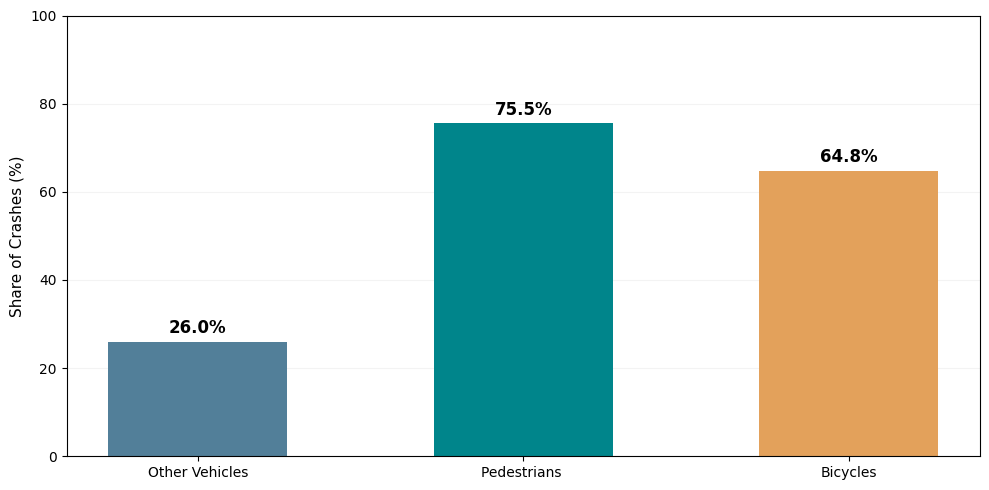

In [ ]:

# Visualise injury-related outcomes by NMF pattern

nmf_injury = nmf_severity['Medical'] + nmf_severity['Hospital']

pattern_order = ['Pattern 1', 'Pattern 2', 'Pattern 3']
pattern_labels = [
    'Other Vehicles',
    'Pedestrians ',
    'Bicycles'
]

percentages = nmf_injury.loc[pattern_order]

colors = ['#527F99', '#00858B', '#E3A15B']

plt.figure(figsize=(10, 5))
bars = plt.bar(
    pattern_labels,
    percentages.values,
    color=colors,
    width=0.55
)

plt.ylabel('Share of Crashes (%)', fontsize=11)
plt.ylim(0, 100)
plt.yticks(range(0, 101, 20))
plt.grid(axis='y', alpha=0.15)
plt.gca().set_axisbelow(True)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f'{height:.1f}%',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

plt.xticks(fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:

# Compare NMF results with original road-user indicators

comparison = feature_df.copy().reset_index(drop=True)

comparison['SEVERITY'] = unique_school_crashes['SEVERITY'].values

# Identify crashes involving pedestrians or bicycles
comparison['Pedestrian Crash'] = comparison['TOTAL_PEDESTRIANS_INVOLVED'] > 0
comparison['Bicycle Crash'] = comparison['TOTAL_BIKE_INVOLVED'] > 0

# Identify medical or hospital crashes
comparison['Medical or Hospital'] = comparison['SEVERITY'].isin(
    ['Medical', 'Hospital']
)

# Compare injury-related severity
for column in ['Pedestrian Crash', 'Bicycle Crash']:
    selected = comparison[comparison[column]]

    print(column)
    print("Number of crashes:", len(selected))
    print(
        "Medical or Hospital (%):",
        round(selected['Medical or Hospital'].mean() * 100, 2)
    )
    print()


Pedestrian Crash
Number of crashes: 194
Medical or Hospital (%): 73.71

Bicycle Crash
Number of crashes: 166
Medical or Hospital (%): 69.28



### 8.10 NMF Findings, Application and Limitations

Non-negative Matrix Factorisation (NMF) was applied to six non-negative road-user involvement features from 5,007 crashes geographically matched to school speed-zone segments in Western Australia.

**Component identification**

The initial two-component model identified patterns dominated by other vehicles and pedestrians. A three-component model additionally separated bicycle involvement into a distinct component.

Reconstruction error decreased from 21.880 with two components to 17.391 with three components. Although additional components further reduced reconstruction error, three components were selected for interpretability rather than as a statistically optimal solution.

**Practical application**

Crashes were grouped by their highest-scoring NMF component for exploratory severity analysis:

- Other-vehicle-dominated pattern: 4,595 crashes; 25.96% Medical or Hospital
- Pedestrian-dominated pattern: 233 crashes; 75.54% Medical or Hospital
- Bicycle-dominated pattern: 179 crashes; 64.80% Medical or Hospital

The original pedestrian and bicycle involvement indicators produced similar severity percentages of 73.71% and 69.28%, respectively.

**Evaluation and limitations**

NMF produced interpretable road-user involvement patterns and demonstrated how extracted components could be examined alongside crash severity. However, the original features already captured much of this information, so substantial additional analytical value was not established.

The data contains many zero values, and dominant-component assignments are sensitive to component scaling. NMF does not establish causal relationships, exposure-adjusted crash risk, or the effectiveness of school-zone speed limits. Geographic matching does not confirm that school-zone restrictions were active at the time of a crash.

**Conclusion:** NMF provides a useful exploratory representation of road-user involvement, complementing PCA, but its results should be interpreted cautiously.


## 9. Location Based Crash Analysis

This section investigates the geographic distribution of historical crashes matched to recorded school speed zone segments in Western Australia.

The aim is to identify roads with higher numbers of recorded crashes that may warrant further road safety investigation.

Crash counts are descriptive and do not represent crash risk because traffic volumes, road lengths and other exposure factors have not been considered.

### 9.1 Roads with the Highest Matched Crash Counts

Matched crash records are grouped by road identifier and road name to identify roads with the highest historical crash counts.

Unique crash identifiers are counted to avoid double counting crashes that may have matched multiple school speed zone records.

The analysis focuses on roads rather than individual speed zone segments initially, as this provides a clearer overview of crash concentrations.


In [ ]:
# Counting unique matched crashes by road
road_crash_counts = school_zone_crashes.groupby(['ROAD_NO', 'ROAD_NAME_x'])['ACC_ID'].nunique()

# Identifying the 10 roads with the highest crash counts
top_10_roads = road_crash_counts.sort_values(ascending=False).head(10)
print("TOP 10 ROADS BY MATCHED CRASH COUNT")
display(top_10_roads)


TOP 10 ROADS BY MATCHED CRASH COUNT


,,ACC_ID
ROAD_NO,ROAD_NAME_x,
1070005,Read St,94
H014,Stirling Hwy,94
1120005,Beechboro Rd North,83
1070128,Warnbro Sound Av,82
H005,Great Eastern Hwy,81
1102151,Connolly Dr,76
1250088,Hutton St,71
1070003,Safety Bay Rd,66
1040001,William St,65



### 9.2 Visualising Roads with the Highest Matched Crash Counts

A horizontal bar chart is used to compare the ten roads with the highest numbers of unique historical crashes matched to recorded school speed zone segments.

The visualisation helps identify roads that may warrant further investigation based on historical crash frequency.

These counts are descriptive and should not be interpreted as a ranking of road safety risk.


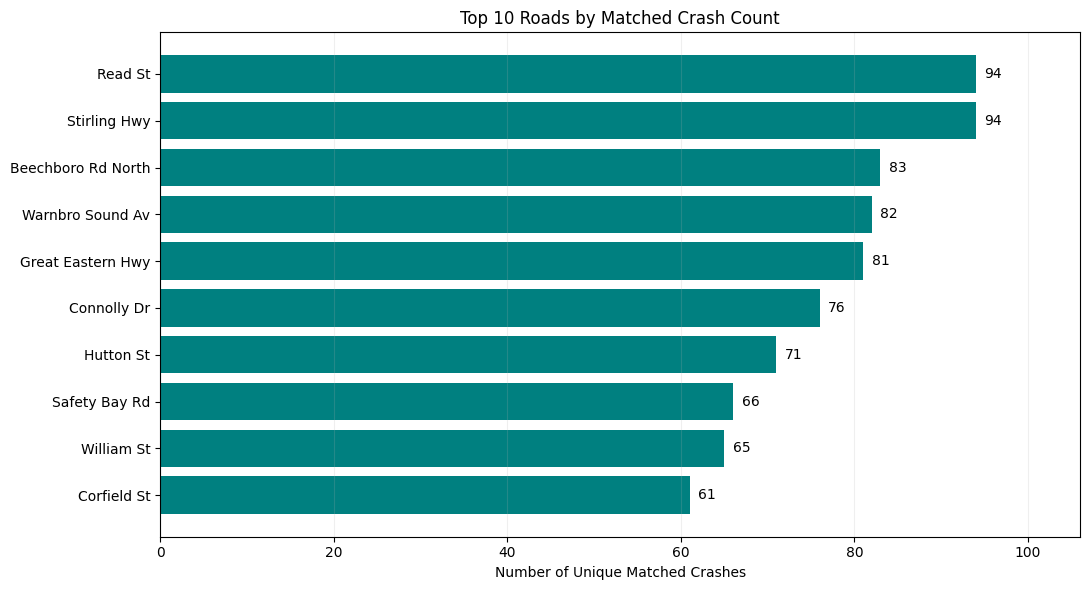

In [ ]:
# Visualising the top 10 roads by matched crash count

road_plot = top_10_roads.sort_values()

plt.figure(figsize=(11, 6))

bars = plt.barh(range(len(road_plot)),road_plot.values,color='teal')

plt.yticks(range(len(road_plot)),[name for road, name in road_plot.index])

plt.xlabel('Number of Unique Matched Crashes')
plt.title('Top 10 Roads by Matched Crash Count')

# Display crash counts at the end of each bar
for bar in bars:
    plt.text(bar.get_width() + 1,bar.get_y() + bar.get_height() / 2,str(int(bar.get_width())),va='center')

plt.xlim(0, road_plot.max() + 12)
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


### 9.3 School Speed Zone Segments with the Highest Matched Crash Counts

The analysis is extended from entire roads to individual school speed zone segments.

Each segment is identified using its road identifier, road name, carriageway classification and start and end SLK positions.

Unique crash identifiers are counted within each segment to identify locations with higher recorded crash frequencies.

A crash may be associated with more than one segment if segment boundaries overlap or share endpoints. Therefore, segment level counts should not be added together to calculate the total number of unique crashes.


In [ ]:

# Counting unique crashes within each school speed-zone segment
segment_crash_counts = school_zone_crashes.groupby(['ROAD', 'ROAD_NAME_y', 'CWY', 'START_SLK', 'END_SLK'])['ACC_ID'].nunique()

# Identifying the 10 segments with the highest crash counts
top_10_segments = segment_crash_counts.sort_values(ascending=False).head(10)

print("TOP 10 SCHOOL SPEED-ZONE SEGMENTS BY MATCHED CRASH COUNT")
display(top_10_segments)


TOP 10 SCHOOL SPEED-ZONE SEGMENTS BY MATCHED CRASH COUNT


,,,,,ACC_ID
ROAD,ROAD_NAME_y,CWY,START_SLK,END_SLK,
1250088,Hutton St,Left,1.490,1.780,63
1120005,Beechboro Rd North,Left,1.040,1.041,60
1070003,Safety Bay Rd,Left,14.960,15.140,49
1300286,Oxford St,Single,1.450,1.630,47
H013,Canning Hwy,Single,12.680,13.040,47
1101403,Marangaroo Dr,Left,1.903,2.291,44
1250052,Central Av,Single,1.110,1.440,43
1102151,Connolly Dr,Left,2.070,2.100,42
1260003,Mill Point Rd,Single,1.430,1.790,41



### 9.4 Validating High Crash Segment Lengths

The ten segments with the highest matched crash counts are examined to assess their recorded lengths.

Segment lengths are calculated using the difference between the start and end SLK positions, converted from kilometres to metres.

This validation is particularly important for very short segments, where high crash counts may require further investigation of the underlying location data.

The calculated lengths describe the recorded segment boundaries and do not independently verify their physical accuracy.


In [ ]:
# Calculating recorded lengths of the top 10 segments
top_segments_df = top_10_segments.reset_index()

top_segments_df['LENGTH_M'] = (top_segments_df['END_SLK'] - top_segments_df['START_SLK']) * 1000
print("TOP 10 SEGMENTS WITH RECORDED LENGTHS")
display(top_segments_df.round(2))

TOP 10 SEGMENTS WITH RECORDED LENGTHS


,ROAD,ROAD_NAME_y,CWY,START_SLK,END_SLK,ACC_ID,LENGTH_M
0,1250088,Hutton St,Left,1.49,1.78,63,290.0
1,1120005,Beechboro Rd North,Left,1.04,1.04,60,1.0
2,1070003,Safety Bay Rd,Left,14.96,15.14,49,180.0
3,1300286,Oxford St,Single,1.45,1.63,47,180.0
4,H013,Canning Hwy,Single,12.68,13.04,47,360.0
5,1101403,Marangaroo Dr,Left,1.90,2.29,44,388.0
6,1250052,Central Av,Single,1.11,1.44,43,330.0
7,1102151,Connolly Dr,Left,2.07,2.10,42,30.0
8,1260003,Mill Point Rd,Single,1.43,1.79,41,360.0
9,H005,Great Eastern Hwy,Single,11.02,11.08,37,60.0



### 9.5 Investigating an Unusually Short Segment

The Beechboro Road North segment recorded 60 matched crashes within an SLK range of 1.040 to 1.041 kilometres, representing a recorded length of approximately one metre.

This unusually high count within a very short segment requires further investigation.

The crash SLK positions will be examined to determine whether the matched records share identical or closely grouped location values.

This check will help assess whether the apparent concentration may be influenced by the precision of the recorded location data.


In [ ]:
# Investigating crash SLK values in the Beechboro Road North segment
beechboro_crashes = school_zone_crashes[
    (school_zone_crashes['ROAD'] == '1120005') & (school_zone_crashes['CWY'] == 'Left') &
    (school_zone_crashes['START_SLK'] == 1.040) & (school_zone_crashes['END_SLK'] == 1.041)]

print("MATCHED CRASHES:", beechboro_crashes['ACC_ID'].nunique())
print("CRASH SLK DISTRIBUTION")
print(beechboro_crashes['SLK'].value_counts().sort_index())

MATCHED CRASHES: 60
CRASH SLK DISTRIBUTION
SLK
1.04    60
Name: count, dtype: int64


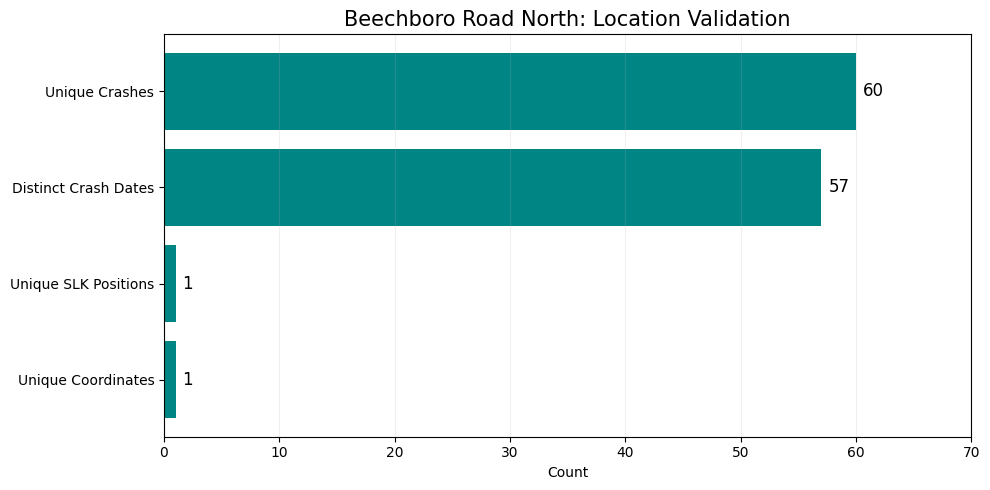

In [ ]:
# Visualising Beechboro Road North location validation

labels = ['Unique Crashes', 'Distinct Crash Dates',
          'Unique SLK Positions', 'Unique Coordinates']

values = [
    beechboro_crashes['ACC_ID'].nunique(),
    beechboro_crashes['CRASH_DATE'].nunique(),
    beechboro_crashes['SLK'].nunique(),
    len(beechboro_crashes[['LATITUDE', 'LONGITUDE']].drop_duplicates())
]

plt.figure(figsize=(10, 5))

bars = plt.barh(labels, values, color='#008585')

plt.bar_label(bars, padding=5, fontsize=12)

plt.title('Beechboro Road North: Location Validation', fontsize=15)
plt.xlabel('Count')
plt.xlim(0, 70)
plt.gca().invert_yaxis()

plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


**Findings — Beechboro Road North Location Validation**

The investigation identified 60 unique crashes matched to a Beechboro Road North segment with a recorded length of approximately one metre.

All 60 crashes shared the same SLK value of 1.040 kilometres.

This concentration may reflect the precision of recorded crash locations or the assignment of multiple crashes to a common road reference position.

Therefore, the result should not be interpreted as evidence that 60 crashes physically occurred within a one-metre section of road.

The segment has been retained in the analysis but flagged for further location validation before drawing road safety conclusions.



### 9.6 Validating Geographic Coordinates

The geographic coordinates of crashes matched to the unusually short Beechboro Road North segment are examined.

The analysis compares the number of unique latitude and longitude values to determine whether crashes sharing the same SLK also share the same recorded geographic position.

This validation helps identify potential limitations in location precision before interpreting crash concentrations.


In [ ]:
# Checking geographic coordinates for Beechboro Road North crashes
print("UNIQUE LATITUDE VALUES:", beechboro_crashes['LATITUDE'].nunique())
print("UNIQUE LONGITUDE VALUES:", beechboro_crashes['LONGITUDE'].nunique())
print("SAMPLE CRASH LOCATIONS")
display(beechboro_crashes[['ACC_ID', 'SLK', 'LATITUDE', 'LONGITUDE']].head(10))

UNIQUE LATITUDE VALUES: 1
UNIQUE LONGITUDE VALUES: 1
SAMPLE CRASH LOCATIONS


,ACC_ID,SLK,LATITUDE,LONGITUDE
280,11164334,1.04,-31.888927,115.924341
8149,11340478,1.04,-31.888927,115.924341
9520,11305783,1.04,-31.888927,115.924341
10336,11307145,1.04,-31.888927,115.924341
12134,11336244,1.04,-31.888927,115.924341
13959,11167494,1.04,-31.888927,115.924341
18332,11183394,1.04,-31.888927,115.924341
18493,11193320,1.04,-31.888927,115.924341
25731,11507091,1.04,-31.888927,115.924341
30272,11415831,1.04,-31.888927,115.924341



**Findings — Geographic Coordinate Validation**

All 60 unique crashes matched to the Beechboro Road North segment shared the same recorded SLK value of 1.040 kilometres and identical geographic coordinates.

The recorded coordinates were latitude -31.888927 and longitude 115.924341.

These findings suggest that multiple crash records may have been assigned to a common geographic reference position.

Although the crashes have different identifiers, the available location information does not establish whether they occurred at precisely the same physical point.

The segment has therefore been flagged for further investigation. The records remain in the dataset, but their apparent spatial concentration should be interpreted cautiously.



### 9.7 Investigating Crash Dates at a Shared Location

The crash dates associated with the Beechboro Road North records are examined to determine whether crashes sharing identical location information were recorded on different dates.

This check helps distinguish repeated crash records at a common reference location from potentially duplicated observations.

Different crash dates would support the interpretation that the records represent separate reported events, although the exact physical crash locations would remain uncertain.


In [ ]:
# Checking crash dates for records sharing the same location
print("UNIQUE CRASH IDs:", beechboro_crashes['ACC_ID'].nunique())
print("UNIQUE CRASH DATES:", beechboro_crashes['CRASH_DATE'].nunique())
print("CRASH DATE DISTRIBUTION")
print(beechboro_crashes['CRASH_DATE'].value_counts().head(10))

UNIQUE CRASH IDs: 60
UNIQUE CRASH DATES: 57
CRASH DATE DISTRIBUTION
CRASH_DATE
29/03/2021    2
09/04/2021    2
19/10/2023    2
18/04/2025    1
20/03/2025    1
10/07/2024    1
27/08/2024    1
19/03/2025    1
10/04/2025    1
02/11/2025    1
Name: count, dtype: int64



**Findings — Crash Date Validation**

The Beechboro Road North investigation identified 60 unique crash records across 57 distinct crash dates.

Although all records shared the same SLK position and geographic coordinates, the different crash dates suggest that they represent multiple reported crash events rather than simple duplicate records.

The repeated location information may reflect how crash positions were recorded or assigned to a common road reference point.

Therefore, the 60 crashes have been retained in the analysis, but the recorded one-metre segment should not be interpreted as a confirmed physical crash hotspot without further location validation.


### 9.8 Comparing Location Precision Across High-Crash Segments

The location validation is extended to the ten school speed-zone segments with the highest matched crash counts.

For each segment, the number of unique recorded crash SLK positions is examined.

This comparison helps identify segments where multiple crash records share the same location reference and highlights potential limitations in spatial precision.

A small number of unique SLK positions does not necessarily indicate incorrect data, but it may require further investigation before interpreting crash concentrations.


In [ ]:
# Counting unique crash SLK positions within each segment
segment_location_counts = school_zone_crashes.groupby(['ROAD', 'ROAD_NAME_y', 'CWY', 'START_SLK', 'END_SLK'])['SLK'].nunique()

# Adding location counts to the top 10 segment table
top_segments_df['UNIQUE_SLK'] = top_segments_df.set_index(['ROAD', 'ROAD_NAME_y', 'CWY', 'START_SLK', 'END_SLK']).index.map(segment_location_counts)

print("LOCATION PRECISION IN TOP 10 SEGMENTS")
display(top_segments_df[['ROAD_NAME_y', 'CWY', 'ACC_ID', 'LENGTH_M', 'UNIQUE_SLK']])

LOCATION PRECISION IN TOP 10 SEGMENTS


,ROAD_NAME_y,CWY,ACC_ID,LENGTH_M,UNIQUE_SLK
0,Hutton St,Left,63,290.0,7
1,Beechboro Rd North,Left,60,1.0,1
2,Safety Bay Rd,Left,49,180.0,2
3,Oxford St,Single,47,180.0,12
4,Canning Hwy,Single,47,360.0,13
5,Marangaroo Dr,Left,44,388.0,2
6,Central Av,Single,43,330.0,4
7,Connolly Dr,Left,42,30.0,1
8,Mill Point Rd,Single,41,360.0,8
9,Great Eastern Hwy,Single,37,60.0,2



### 9.9 Location Based Findings and Limitations

The location based analysis identified roads and individual school speed zone segments with higher numbers of geographically matched historical crashes.

At the road level, Read Street and Stirling Highway recorded the highest matched crash counts, with 94 unique crashes each.

At the segment level, Hutton Street recorded 63 matched crashes, followed by Beechboro Road North with 60 crashes.

Further investigation identified potential limitations in the recorded crash locations. All 60 Beechboro Road North crashes shared the same SLK value and geographic coordinates, despite occurring across 57 distinct dates.

Similar patterns were observed on other segments. Connolly Drive had 42 matched crashes at one recorded SLK position, while Safety Bay Road and Marangaroo Drive each had crashes distributed across only two recorded SLK positions.

These findings indicate that repeated location references may influence the apparent concentration of crashes within individual segments.

**Limitations**

- High crash counts do not necessarily indicate higher crash risk because traffic exposure has not been considered.
- Identical SLK positions do not confirm that crashes occurred at precisely the same physical location.
- The accuracy of recorded segment boundaries and geographic coordinates has not been independently verified.
- Historical changes to school speed-zone boundaries and operating conditions remain unknown.
- Segment level counts may include crashes associated with multiple recorded segments.

**Recommendations**

Roads and segments with higher matched crash counts may warrant further investigation using more detailed crash location records, road geometry, traffic volumes and historical speed zone information.

Particular attention should be given to validating repeated location references before identifying physical crash hotspots or recommending changes to speed limits.

Overall, the location based analysis provides a useful starting point for prioritising further road safety investigations, while highlighting the importance of validating geographic data.



### 9.10 Crash Characteristics at Repeated Locations

The analysis investigates accident types and crash severity classifications for the 60 Beechboro Road North records that share identical SLK positions and geographic coordinates.

The purpose is to determine whether these records contain different reported crash characteristics despite sharing the same recorded location.

Differences in accident type and severity may provide additional evidence that the records describe different crash events. However, these differences do not independently confirm the accuracy of the recorded geographic positions.


In [ ]:
# Investigating accident types and severity at the shared location
print("ACCIDENT TYPE DISTRIBUTION")
print(beechboro_crashes['ACCIDENT_TYPE'].value_counts())
print("\nCRASH SEVERITY DISTRIBUTION")
print(beechboro_crashes['SEVERITY'].value_counts())

ACCIDENT TYPE DISTRIBUTION
ACCIDENT_TYPE
Intersection    60
Name: count, dtype: int64

CRASH SEVERITY DISTRIBUTION
SEVERITY
PDO Major    27
Medical      15
PDO Minor    14
Hospital      4
Name: count, dtype: int64



**Findings — Crash Characteristics at a Shared Location**

The investigation found that all 60 Beechboro Road North crashes were classified as intersection crashes.

The severity distribution included 27 PDO Major crashes, 15 Medical crashes, 14 PDO Minor crashes and 4 Hospital crashes.

Although these records shared identical SLK positions and geographic coordinates, they occurred across 57 different dates and included different severity classifications.

The consistent intersection classification suggests that the shared location may represent a common intersection reference point rather than 60 crashes occurring within a physical one metre road segment.

However, this interpretation requires further validation using intersection details and road geometry.

The records were retained because the available evidence does not establish that they are duplicates or incorrectly recorded.



### 9.11 Testing and Validation Summary

Several validation checks were performed throughout the project to assess data quality and the reliability of the analysis.

- **Data completeness:** Missing values were identified and investigated. Records were not automatically removed because some missing information may be legitimate.
- **Duplicate records:** Duplicate rows and crash identifiers were checked before analysis.
- **Road segment validation:** Segment boundaries, lengths and potential overlaps were examined. No overlapping school speed zone segments were identified using the defined overlap criteria.
- **Geographic matching:** Crashes were matched using road identifiers, carriageway classifications and SLK positions. Unique crash identifiers were used to avoid double counting.
- **Crash time validation:** Crash times were checked for invalid hours and minutes. No invalid non-missing times were identified in the matched records.
- **Location accuracy:** Unusually high crash concentrations were investigated. The Beechboro Road North analysis identified 60 crashes sharing the same recorded SLK and geographic coordinates.

These checks improved confidence in the consistency of the processed data and helped identify limitations in the recorded crash locations.

However, successful validation does not guarantee that all source records are geographically accurate or that school speed restrictions were active when crashes occurred.


## 9.12 Crash Characteristics and Contributing Factors

This section examines how crashes occurred using EVENT_NATURE,
EVENT_TYPE and ACCIDENT_TYPE.

The aim is to identify common crash patterns that may help inform
road safety and speed management policies.

These fields describe recorded crash circumstances, not confirmed
root causes such as speeding, distraction or driver behaviour.

In [ ]:
# Examining recorded crash characteristics

crash_columns = ['EVENT_NATURE', 'EVENT_TYPE', 'ACCIDENT_TYPE']

for column in crash_columns:
    print("\n", column)
    print(crash_df[column].value_counts(dropna=False))


 EVENT_NATURE
EVENT_NATURE
Rear End               55211
Right Angle            30407
Sideswipe Same Dirn    17771
NaN                     8347
Right Turn Thru         7611
Hit Object              6843
Non Collision           2592
Hit Pedestrian          1482
Head On                 1350
Hit Animal              1248
Name: count, dtype: int64

 EVENT_TYPE
EVENT_TYPE
NaN                            98004
Involving Overtaking           12990
Involving Parking               9921
Entering / Leaving Driveway     7932
Involving Animal                2252
Involving Pedestrian            1763
Name: count, dtype: int64

 ACCIDENT_TYPE
ACCIDENT_TYPE
Intersection                   71519
Midblock                       61342
Roads Open To Public Access        1
Name: count, dtype: int64


### 9.12.1 Crash Types in Matched School Zones and Other Roads

This analysis compares the recorded types of crashes in matched
school zone segments with crashes on other roads.

Percentages are used because the two groups contain different
numbers of crashes.

The comparison describes crash patterns and does not establish
that school speed limits caused or prevented crashes.

In [ ]:
# Comparing crash types between matched school zones and other roads
crash_nature_comparison = pd.crosstab(crash_df['EVENT_NATURE'], crash_df['ZONE_GROUP'], normalize='columns') * 100
print("CRASH TYPE COMPARISON (%)")
display(crash_nature_comparison.round(2))

CRASH TYPE COMPARISON (%)


ZONE_GROUP,Matched School Zone,Other Roads
EVENT_NATURE,,
Head On,0.97,1.09
Hit Animal,0.26,1.03
Hit Object,4.91,5.52
Hit Pedestrian,3.33,1.11
Non Collision,1.00,2.12
Rear End,34.11,44.74
Right Angle,37.63,23.91
Right Turn Thru,6.41,6.10
Sideswipe Same Dirn,11.38,14.38


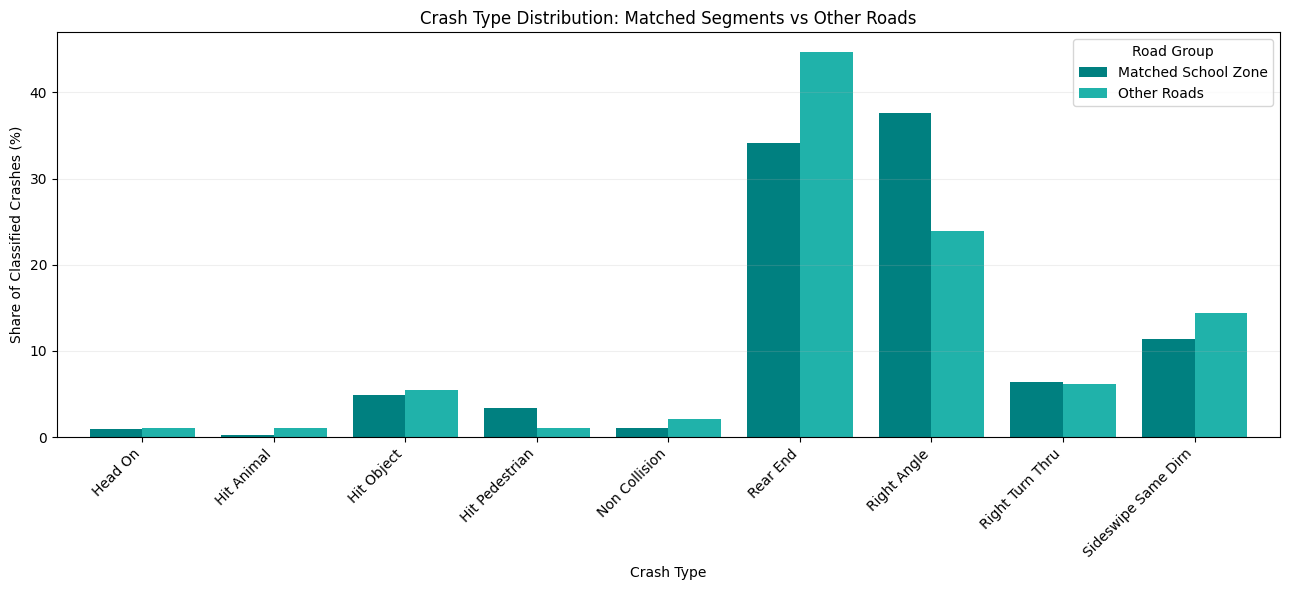

In [ ]:

# Visualising crash types: matched segments vs other roads

ax = crash_nature_comparison.plot(
    kind='bar',
    figsize=(13, 6),
    width=0.8,
    color=['teal', 'lightseagreen']
)

plt.title('Crash Type Distribution: Matched Segments vs Other Roads')
plt.xlabel('Crash Type')
plt.ylabel('Share of Classified Crashes (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Road Group')
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()


**Findings:**

Right-angle crashes account for a larger proportion of recorded
crash types in matched school-zone segments (37.63%) than on
other roads (23.91%).

Pedestrian crashes also represent a higher proportion in matched
school-zone segments (3.33% compared with 1.11%).

Rear-end crashes are more common proportionally on other roads
(44.74% compared with 34.11%).

These results suggest that intersection safety and pedestrian
protection are useful areas for further investigation.

However, the comparison does not confirm that school-zone speed
limits were active when these crashes occurred.


### 9.12.2 Intersection and Midblock Crash Comparison

In [ ]:
# Comparing accident locations between matched school zones and other roads
accident_type_comparison = pd.crosstab(crash_df['ACCIDENT_TYPE'],crash_df['ZONE_GROUP'],normalize='columns') * 100
print("ACCIDENT LOCATION COMPARISON (%)")
display(accident_type_comparison.round(2))

ACCIDENT LOCATION COMPARISON (%)


ZONE_GROUP,Matched School Zone,Other Roads
ACCIDENT_TYPE,,
Intersection,56.62,53.72
Midblock,43.38,46.28
Roads Open To Public Access,0.00,0.00


**Findings:**

Intersection crashes account for 56.62% of crashes in matched
school-zone segments, compared with 53.72% on other roads.

The difference is relatively small. However, right-angle crashes
represent a noticeably higher proportion in matched school-zone
segments.

This suggests that intersection crash characteristics deserve
further investigation when considering road safety policies.

These results describe crash distributions, not the risk of
crashing at an intersection.

### 9.12.3 Crash Types at Intersections in Matched School Zones

In [ ]:
# Investigating crash types at intersections in matched school zones
school_intersections = unique_school_crashes[unique_school_crashes['ACCIDENT_TYPE'] == 'Intersection']
print("CRASH TYPES AT MATCHED SCHOOL-ZONE INTERSECTIONS")
print(school_intersections['EVENT_NATURE'].value_counts())

# Percentage distribution
print("\nCRASH TYPE DISTRIBUTION (%)")
print(school_intersections['EVENT_NATURE'].value_counts(normalize=True).mul(100).round(2))

CRASH TYPES AT MATCHED SCHOOL-ZONE INTERSECTIONS
EVENT_NATURE
Right Angle            1283
Rear End                891
Right Turn Thru         252
Sideswipe Same Dirn     151
Hit Object              104
Non Collision            31
Hit Pedestrian           31
Head On                  12
Name: count, dtype: int64

CRASH TYPE DISTRIBUTION (%)
EVENT_NATURE
Right Angle            46.57
Rear End               32.34
Right Turn Thru         9.15
Sideswipe Same Dirn     5.48
Hit Object              3.77
Non Collision           1.13
Hit Pedestrian          1.13
Head On                 0.44
Name: proportion, dtype: float64


**Findings:**

Right-angle crashes are the most common recorded crash type at
intersections within matched school-zone segments, accounting
for 46.57% of classified crashes (1,283 crashes).

Rear-end crashes are the second most common type at 32.34%,
followed by right-turn-through crashes at 9.15%.

These findings suggest that intersection safety should be
considered when developing road safety policies.

Possible areas for further investigation include intersection
design, visibility, turning movements and speed management.

However, the data does not identify the actual cause of these
crashes or confirm that school-zone speed limits were active.

### 9.12.4 Morning vs Afternoon Crash Type Comparison

This analysis compares recorded crash types during weekday morning
and afternoon school-travel periods in matched school-zone segments.

Percentages are used to compare the distribution of crash types
between the two periods.

These periods do not confirm that school-zone speed restrictions
were active on the crash dates.

In [ ]:
# Comparing crash types during morning and afternoon school travel periods

morning_nature = morning_crashes['EVENT_NATURE'].value_counts(normalize=True) * 100
afternoon_nature = afternoon_crashes['EVENT_NATURE'].value_counts(normalize=True) * 100

time_nature_comparison = pd.DataFrame({'Morning (%)': morning_nature,'Afternoon (%)': afternoon_nature})
print("MORNING VS AFTERNOON CRASH TYPE COMPARISON (%)")
display(time_nature_comparison.fillna(0).round(2))

MORNING VS AFTERNOON CRASH TYPE COMPARISON (%)


,Morning (%),Afternoon (%)
EVENT_NATURE,,
Head On,0.42,1.22
Hit Object,1.97,2.93
Hit Pedestrian,5.49,6.85
Non Collision,0.56,0.24
Rear End,35.21,40.34
Right Angle,38.03,31.42
Right Turn Thru,4.93,3.30
Sideswipe Same Dirn,13.38,13.69


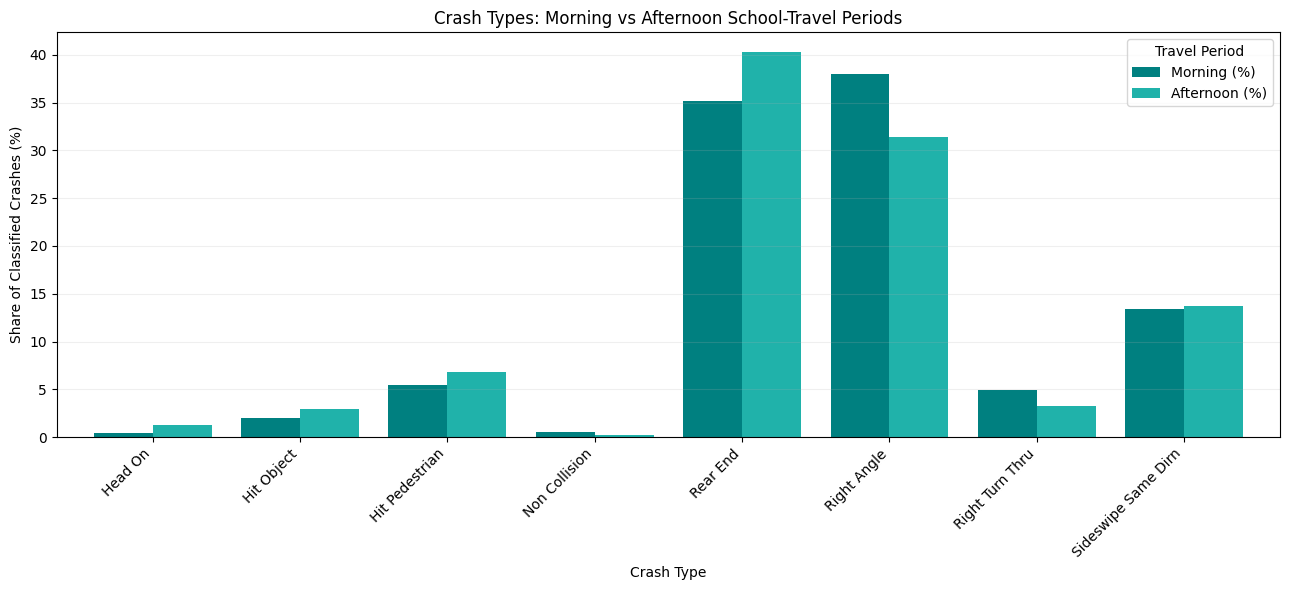

In [ ]:

# Comparing all crash types by school-travel period

ax = time_nature_comparison.fillna(0).plot(
    kind='bar',
    figsize=(13, 6),
    width=0.8,
    color=['teal', 'lightseagreen']
)

plt.title('Crash Types: Morning vs Afternoon School-Travel Periods')
plt.xlabel('Crash Type')
plt.ylabel('Share of Classified Crashes (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Travel Period')
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()


**Findings:**

Right-angle crashes represent a higher proportion during the
morning school-travel period (38.03%) than the afternoon (31.42%).

Rear-end crashes are more common proportionally in the afternoon
(40.34%) compared with the morning (35.21%).

Pedestrian crashes also account for a slightly higher proportion
in the afternoon (6.85%) than the morning (5.49%).

These differences suggest that intersection safety and traffic
management during school-travel periods are worth investigating
when considering road safety policies.

However, these are weekday time-based comparisons. They do not
confirm that school-zone restrictions were active or identify
the actual causes of the crashes.

### 9.12.5 Road Safety and Speed-Limit Policy Recommendations

The analysis identified several crash patterns that may help
guide future road safety policies in Western Australia.

**1. Intersection Safety**

Right-angle crashes account for 46.57% of classified crashes
at intersections within matched school-zone segments.

This suggests that intersection design, visibility, turning
movements and speed management should be investigated.

**2. Morning School-Travel Period**

Right-angle crashes represent 38.03% of classified crashes
during the morning period, compared with 31.42% in the afternoon.

Road authorities could investigate whether intersection
improvements or additional speed-management measures are needed
during morning school-travel periods.

**3. Afternoon Traffic Management**

Rear-end crashes represent 40.34% of classified crashes during
the afternoon period, compared with 35.21% in the morning.

This suggests that traffic congestion, vehicle spacing and
intersection approaches could be investigated to identify
potential safety improvements.

**4. Pedestrian Safety**

Pedestrian crashes represent a larger proportion of classified
crashes in matched school-zone segments (3.33%) than on other
roads (1.11%).

Possible improvements include reviewing pedestrian crossings,
visibility, signage and existing school-zone speed restrictions.

### Policy Limitations

These recommendations identify areas for further investigation,
not proven solutions.

The datasets do not contain actual vehicle speeds, driver
distraction, traffic volumes or confirmed active school-zone
conditions for each crash.

Historical changes to school-zone boundaries may also affect
the matching results.

Therefore, this project cannot identify confirmed root causes
or determine whether changing a speed limit would reduce crashes.

Further investigation would be needed before implementing
specific speed-limit changes.


## 10. Overall Findings and Discussion

This section brings together the main findings from the road crash analysis, school speed zone matching, temporal analysis, PCA and NMF.

The findings are discussed in relation to the project objective of identifying historical crash patterns that may help inform road safety investigations and policy considerations in Western Australia.

### 10.1 Summary of Key Findings

**Geographic Matching**

The analysis identified 5,007 unique historical crashes geographically matched to recorded school speed zone segments using road identifiers, carriageway classifications and SLK positions.

These matches indicate crash locations within recorded road segments, but do not confirm that school speed restrictions were active at the time of each crash.

**Crash Severity**

The matched records included 2,257 PDO Major crashes, 1,256 PDO Minor crashes, 1,255 Medical crashes, 230 Hospital crashes and 9 Fatal crashes.

Property damage only crashes accounted for the largest proportion of matched records, while fatal crashes represented a relatively small number of observations.

**School Travel Periods**

During approximate weekday school travel periods, 777 crashes were recorded between 7:30 AM and 9:00 AM, compared with 907 crashes between 2:30 PM and 4:00 PM.

Pedestrian involved crashes totalled 47 during the morning period and 64 during the afternoon period.

These comparisons describe recorded crash counts and do not account for traffic exposure, school holidays or historical school speed zone operating schedules.

**Annual and Monthly Patterns**

Annual matched crash totals ranged from 962 in 2022 to 1,058 in 2024 across the analysed 2021–2025 period.

The monthly analysis indicated higher crash counts around May and June, while January recorded fewer crashes.

These patterns may be useful for further investigation but cannot independently establish seasonal causes or changes in crash risk.

**Principal Component Analysis (PCA)**

PCA was applied to six standardised road-user involvement features. The first two principal components explained approximately 40.86% of the total feature variance, while five components retained 90.86%.

K-Means clustering was subsequently applied to the five-component PCA representation to investigate patterns in road-user involvement. The three-cluster model identified groups containing 4,182, 807 and 18 crashes.

The cluster containing 807 crashes had a higher proportion of Medical and Hospital severity outcomes (61.34%) than the largest cluster (23.62%).

However, clustering on the original standardised features produced a higher silhouette score (0.769) than PCA-based clustering (0.728). Testing five PCA-based clusters increased the silhouette score to 0.842, but 91.17% of crashes belonged to one cluster.

These results demonstrate an application of PCA for dimensionality reduction and clustering, although PCA did not improve clustering separation for this dataset. The highly repetitive feature combinations and imbalanced cluster sizes limit the interpretation of the results.

**Non-negative Matrix Factorisation (NMF)**

NMF was applied to the six non-negative road-user involvement features. The three-component model identified interpretable patterns dominated by other vehicles, pedestrians and bicycles.

The reconstruction error decreased from 21.880 with two components to 17.391 with three components. Three components were selected for interpretability rather than as a statistically optimal solution.

An exploratory analysis of dominant NMF patterns showed that 75.54% of crashes in the pedestrian-dominated group and 64.80% in the bicycle-dominated group were classified as Medical or Hospital, compared with 25.96% in the other-vehicle-dominated group.

However, analysis of the original pedestrian and bicycle involvement indicators produced similar percentages of 73.71% and 69.28%, respectively.

NMF therefore provided an interpretable representation of road-user involvement patterns, but did not demonstrate substantial additional analytical value beyond the original features. The pattern assignments are exploratory and sensitive to component scaling.


### 10.2 Discussion and Road Safety Policy Implications

The findings provide insights into historical crash patterns within road segments identified as school speed zones in the available dataset.

**Identifying Locations for Further Investigation**

The geographic matching process identified 5,007 unique crashes within recorded school speed-zone segments.

The additional location based analysis identified Read Street and Stirling Highway as the roads with the highest matched crash counts, while Hutton Street and Beechboro Road North contained the individual segments with the highest recorded counts.

These results provide a starting point for identifying locations that may warrant further road safety assessment.

However, the investigation of Beechboro Road North revealed that 60 crashes were associated with a recorded one metre segment and identical geographic coordinates. All records were classified as intersection crashes, suggesting that the location may represent a common intersection reference point.

Similar patterns of repeated SLK positions were observed on other roads, indicating that apparent crash concentrations may be influenced by how locations are recorded.

Therefore, the identified roads and segments should be treated as candidates for further investigation rather than confirmed high-risk locations.

More detailed geographic information, intersection layouts, historical speed-zone records, traffic volumes and pedestrian activity would be required before recommending specific road safety interventions.

**School Travel Periods**

The analysis recorded more crashes during the approximate afternoon school travel period (907) than the morning period (777). Pedestrian-involved crashes were also more frequent in the afternoon period (64) than in the morning (47).

These findings suggest that afternoon travel conditions may be worth investigating further, particularly where students and other pedestrians interact with vehicles.

However, the analysis does not establish whether school speed limits were active during these crashes or whether the differences reflect traffic volumes and exposure.

**Road User Involvement**

PCA and NMF were applied to six road-user involvement features to investigate patterns among geographically matched crashes.

PCA followed by K-Means clustering identified groups with different severity distributions, although PCA did not improve cluster separation compared with the original standardised features.

NMF identified patterns dominated by other vehicles, pedestrians and bicycles. Medical and Hospital outcomes accounted for 75.54% of crashes assigned to the pedestrian-dominated pattern and 64.80% of crashes assigned to the bicycle-dominated pattern, compared with 25.96% in the other-vehicle-dominated pattern.

However, comparisons using the original pedestrian and bicycle involvement indicators produced similar results, indicating that NMF added limited information beyond the existing features.

These findings support further investigation of pedestrian and cyclist safety. They do not establish causation, exposure-adjusted crash risk or the effectiveness of school speed-zone restrictions.

**Potential Road Safety Policy Applications**

The analysis may support further road safety investigations by:

- Identifying road segments and intersections that warrant detailed crash-location validation and safety assessment.
- Supporting reviews of pedestrian and cyclist safety near schools, particularly during approximate school travel periods.
- Highlighting locations where additional traffic-volume, vehicle-speed and pedestrian-activity observations may be valuable.
- Informing assessments of school speed-zone boundaries, signage, operating schedules and surrounding road design.
- Supporting future investigations into whether speed-management measures could improve safety at selected locations.

Before recommending specific speed-limit changes, further evidence would be required, including historical speed limits, operating schedules, school calendars, traffic volumes, vehicle speeds and road conditions.

Locations with repeated crash coordinates or identical SLK positions should be validated before being classified as crash hotspots or prioritised for interventions.

Overall, the project demonstrates how combining crash records with road network information can support evidence informed road safety planning. Its findings should be treated as exploratory evidence rather than proof of the effectiveness or failure of existing school speed zone policies.



### 10.3 Study Limitations and Recommendations for Future Analysis

Although the project identified useful patterns in historical road crash records, several limitations should be considered when interpreting the results.

**Dataset Limitations**

The analysis used historical crash records and available legal speed zone information. The speed zone dataset does not establish whether the same restrictions were in place on each historical crash date.

Some crash attributes also contained missing values, particularly `EVENT_TYPE`, `INTERSECTION_NO` and `INTERSECTION_DESC`. These incomplete records may limit the interpretation of certain crash characteristics.

**Geographic Matching Limitations**

Crashes were matched to school speed zone segments using road identifiers, carriageway classifications and SLK positions.

This approach identifies crashes within recorded road segments but does not independently verify their precise location or whether a school speed restriction was active at the time.

The additional location analysis also identified repeated crash coordinates and SLK positions. For example, 60 crashes were associated with a recorded one-metre segment on Beechboro Road North, with identical coordinates and intersection classifications. This suggests that some apparent crash concentrations may reflect common intersection reference points rather than precisely distributed crash locations. Consequently, identified hotspots require geographic validation before being used to prioritise road safety interventions.

**Time-Based Analysis Limitations**

The morning and afternoon comparisons used approximate weekday school travel periods.

The analysis did not account for school holidays, public holidays, individual school operating schedules or historical changes to school speed zone hours.

The recorded crash counts were also not adjusted for traffic volumes, pedestrian activity or other measures of road user exposure.

**PCA and NMF Limitations**

PCA and NMF were applied to six road-user involvement features containing many zero values and only 38 unique feature combinations among 5,007 matched crashes. These characteristics limited the complexity of patterns available for analysis.

PCA retained 90.86% of the total feature variance using five components. However, PCA-based K-Means clustering did not improve cluster separation compared with clustering the original standardised features. The three-cluster silhouette scores were 0.728 with PCA and 0.769 without PCA. Increasing the number of PCA-based clusters produced highly imbalanced groups, limiting their practical interpretation.

NMF identified interpretable pedestrian-, bicycle- and other-vehicle-dominated patterns associated with different crash severity distributions. However, similar findings were obtained directly from the original pedestrian and bicycle involvement indicators, suggesting limited additional analytical value.

Both techniques were exploratory. Neither established causal relationships, exposure-adjusted crash risk or the effectiveness of school speed-zone policies. NMF dominant-component assignments were also sensitive to component scaling.

**Recommendations for Future Analysis**

Future investigations could improve the analysis by:

- Incorporating historical speed zone records and verified operating schedules.
- Including school calendars and public holidays when examining school travel periods.
- Using traffic volumes and pedestrian counts to calculate exposure-adjusted crash rates.
- Investigating individual road segments with repeated historical crashes.
- Including vehicle speed measurements and additional road design information.
- Examining crash severity and road user involvement using additional statistical methods.

These improvements could help determine whether the observed patterns remain consistent when additional road, traffic and temporal information is considered.



## 11. Conclusion and Reflection

This section summarises the project's main outcomes, addresses the original research question and reflects on the data analysis techniques applied throughout the investigation.

### 11.1 Project Conclusion

This project investigated historical road crash patterns in Western Australia by combining crash records with legal speed-zone information.

The analysis identified 5,007 unique crashes geographically matched to recorded school speed-zone segments. It examined crash severity, road-user involvement, approximate school travel periods, annual and monthly patterns, and geographic crash concentrations.

The time-based analysis recorded more matched crashes during the approximate afternoon school travel period than during the morning period. However, these counts do not establish differences in crash risk because traffic exposure and historical school-zone operating conditions were not available.

PCA and NMF were applied to six road-user involvement features to investigate underlying patterns. PCA retained 90.86% of the feature variance using five components, but PCA-based K-Means clustering did not improve cluster separation compared with clustering the original standardised features.

NMF identified interpretable patterns dominated by other vehicles, pedestrians and bicycles. However, comparisons with the original involvement indicators produced similar severity findings, suggesting that NMF provided limited additional analytical value.

These results demonstrated the practical application of dimensionality reduction and pattern identification, while also highlighting the importance of evaluating whether machine learning techniques add useful information.

The location-based analysis identified roads and segments with higher historical crash counts. Further investigation revealed that some crashes shared identical SLK positions and geographic coordinates, highlighting limitations in recorded location information.

The crash-characteristics analysis provided additional findings that may help inform road safety policies. Right-angle crashes represented 37.63% of classified crashes in matched school-zone segments, compared with 23.91% on other roads. Pedestrian crashes also accounted for a higher proportion in matched school-zone segments (3.33% compared with 1.11%). These percentages describe differences in the distribution of classified crash types rather than exposure-adjusted crash rates. They do not establish that school speed-zone segments have a higher crash risk than other roads.

Further investigation showed that right-angle crashes accounted for 46.57% of classified intersection crashes in matched school-zone segments. During approximate weekday school-travel periods, right-angle crashes were more prominent in the morning (38.03%), while rear-end crashes were more prominent in the afternoon (40.34%).

These findings suggest that intersection safety, pedestrian protection and traffic management are useful priorities for further investigation. Possible measures include reviewing intersection design, pedestrian crossings, visibility and speed management. However, these are potential policy considerations rather than proven solutions.

**Answer to the Research Question**

Historical crash records and school speed-zone information can be combined to identify crash patterns, examine road-user involvement and highlight locations that may require further road safety investigation.

The analysis found that right-angle and pedestrian crashes represented a larger proportion of classified crashes in matched school-zone segments than on other roads. It also identified differences in crash types between morning and afternoon school-travel periods.

These findings can help road authorities identify where to investigate intersection design, pedestrian safety and speed management. They provide a starting point for developing evidence-informed road safety policies.

However, the analysis is observational and cannot identify confirmed root causes such as speeding, driver distraction or unsafe driving behaviour. Geographic matching also does not prove that a 40 km/h school-zone restriction existed or was active when a crash occurred.

Additional information about historical speed limits, school calendars, traffic volumes, actual vehicle speeds and road conditions would be needed before recommending specific changes to speed limits.

Overall, the project demonstrates how data cleaning, geographic matching, exploratory analysis and machine learning techniques can support road safety investigations while recognising the limitations of the available data.


### 11.2 Project Reflection

Throughout this project, I developed practical experience in data cleaning, exploratory data analysis, dataset merging, feature engineering, data visualisation and machine learning techniques using Python.

**Data Cleaning and Exploration**

One of the main challenges was understanding the structure and quality of two different datasets. I investigated missing values, duplicate records, data types and inconsistent column names.

I learned that missing values should not always be removed automatically, as their importance depends on the purpose of each column and the analysis being performed.

**Dataset Merging and Feature Engineering**

Combining the crash and speed-zone datasets required identifying common road identifiers, standardising carriageway classifications and matching crash SLK positions to recorded speed-zone boundaries.

This helped me understand why validating matching conditions is important, particularly when one crash can match multiple records.

I also created additional features such as crash hour, day of the week, month and year to investigate temporal patterns.

**PCA and NMF**

Applying PCA and NMF helped me understand how machine learning techniques can be used to explore patterns in numerical data.

PCA demonstrated the importance of standardisation, explained variance and evaluating clustering results. Although PCA reduced the number of features, it did not improve clustering separation compared with the original standardised data.

NMF helped identify interpretable road-user involvement patterns, while reconstruction error demonstrated the trade-off between using fewer components and retaining information. However, comparing the NMF results with the original involvement indicators showed that the additional analytical value was limited.

I learned that applying a machine learning technique does not automatically improve an analysis. Its usefulness should be assessed by comparing the results with simpler methods and considering the characteristics of the dataset.

**Crash Characteristics and Policy Analysis**

Analysing EVENT_NATURE and ACCIDENT_TYPE helped me understand the difference between identifying crash patterns and determining the actual causes of crashes.

I found that right-angle crashes were more prominent in matched school-zone segments, particularly at intersections. Comparing morning and afternoon periods also showed differences in the types of crashes recorded.

This helped me connect the results of my analysis to possible road safety improvements rather than simply reporting crash numbers.

I also learned that the available data cannot confirm whether speeding, distraction or other driver behaviours caused these crashes. This is important when making policy recommendations.

**Location Based Data Validation**

One of the most interesting findings was the repeated location information in the Beechboro Road North crash records.

Although 60 crashes were matched to a recorded one-metre segment, further investigation showed that they shared the same SLK and geographic coordinates but occurred across 57 different dates.

This demonstrated why unusual results should be investigated before drawing conclusions.

**Challenges and Improvements**

The main challenges included missing data, differences between dataset structures, repeated geographic references and interpreting machine learning results without overstating their significance.

If I continued this project, I would investigate additional datasets containing historical speed limits, traffic volumes, school calendars and more detailed crash location information.

**Overall Reflection**

This project improved my confidence in using Python, Pandas, Matplotlib, Seaborn and Scikit-learn for data analysis.

More importantly, I learned that producing graphs and statistical results is only one part of the process. Understanding data quality, validating unusual findings and communicating limitations are equally important when using data to support real-world decisions.
